In [ ]:
import sys, os
sys.path.insert(0, os.path.expanduser('~'))
# import mpl_theme; mpl_theme.apply();

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
plt.rc("pdf", fonttype=42)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]
plt.rcParams["font.size"] = 6
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.linewidth"] = 0.25
plt.rcParams["axes.titlesize"] = 6
plt.rcParams["axes.labelsize"] = 6
plt.rcParams["xtick.major.width"] = 0.25
plt.rcParams["xtick.labelsize"] = 6
plt.rcParams["ytick.major.width"] = 0.25
plt.rcParams["ytick.labelsize"] = 6
plt.rcParams["legend.fontsize"] = 6
plt.rcParams["legend.frameon"] = False
plt.rcParams["legend.facecolor"] = "none"
plt.rcParams["lines.linewidth"] = 1.00
plt.rcParams["text.usetex"] = False
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["ps.useafm"] = True

%config InlineBackend.figure_format='retina'

import numpy as np
import pandas as pd

import pickle
import glob

from utils import *
from analysis_utils import *

from tqdm import tqdm

from scipy import stats
import itertools

figures_path = './bild_outputs/figures'


## Load inference data

In [ ]:
conditions = ['unt', 'dCtcf', 'dRad21', 'txn', 'trp']
colors_dict = {
    'unt': '#BBBBBB',
    'txn': '#0077BB',
    'trp': '#ee7733',
    'dRad21': '#33bbee',
    'dCtcf': '#cc3311'
    }
names_dict = {
    'unt': 'untreated',
    'txn': '+ABA',
    'trp': '+ABA +triptolide',
    'dRad21': '\u0394RAD21 (4h)',
    'dCtcf': '\u0394CTCF (4h)'
    }

final_inferences_all = {}
track_names_all = {}

for condition in conditions:
    save_folder = f'./bild_outputs/bild_profiles/{condition}_initial_dE_2.0'

    filenames = [os.path.basename(fn) for fn in glob.glob(os.path.join(save_folder,'*'))]

    profile_info = []
    for fn in filenames:
        track_name, suffix = fn.split('_bild_result_frame_')
        frames_str = suffix[:-4]
        start_frame, end_frame = frames_str.split('_to_')
        start_frame = int(start_frame)
        end_frame = int(end_frame)
        profile_info.append({'track_name': track_name,
                            'start_frame': start_frame,
                            'end_frame': end_frame,
                            'filename': fn})
        
    profile_info = pd.DataFrame(profile_info)
    profile_info = profile_info.sort_values(['track_name', 'start_frame'])
    profile_info.index = np.arange(len(profile_info))

    track_names = np.unique(profile_info['track_name'])

    max_unchopped_traj_len = np.max(profile_info['end_frame'])

    # make matrix to store inferences; store multiple inferences along 3rd dimension
    inferences = np.zeros((len(track_names), max_unchopped_traj_len, 2), dtype='int8') * np.nan
    dist_from_end = np.zeros(inferences.shape, dtype='int') * np.nan

    dE = 2
    for track_name_idx in range(len(track_names)):
        track_name = track_names[track_name_idx]
        profiles_this_track = profile_info.loc[profile_info['track_name']==track_name]
        for i in range(len(profiles_this_track)):
            track_name, start_frame, end_frame, fn = profiles_this_track.iloc[i]
            bild_result = pickle.load(open(os.path.join(save_folder, fn), 'rb'))
            best_profile = bild_result.best_profile(dE=dE)
            best_profile = np.array(list(best_profile)).astype('int8')
            best_profile = pd.Series(best_profile, index=np.arange(start_frame, end_frame))
            for frame_num in range(start_frame, end_frame):
                k = 0
                while not np.isnan(inferences[track_name_idx, frame_num, k]):
                    k += 1
                    if k > inferences.shape[2]:
                        raise RuntimeError('3rd dimension of inferences not large enough!')
                inferences[track_name_idx, frame_num, k] = best_profile[frame_num]
                dist_from_end[track_name_idx, frame_num, k] = min(frame_num-start_frame, end_frame-frame_num)

    final_inferences = np.zeros((inferences.shape[0], inferences.shape[1])) * np.nan
    for track_name_idx in range(len(track_names)):
        for frame_num in range(max_unchopped_traj_len):
            inf1 = inferences[track_name_idx, frame_num, 0]
            inf2 = inferences[track_name_idx, frame_num, 1]
            if np.isnan(inf1) and np.isnan(inf2):
                inf = np.nan
            elif np.isnan(inf2):
                inf = inf1
            elif inf1 != inf2:
                if dist_from_end[track_name_idx, frame_num, 0] > dist_from_end[track_name_idx, frame_num, 1]:
                    inf = inf1
                else:
                    inf = inf2
            else:
                inf = inf1  # doesn't matter, they will be the same
            final_inferences[track_name_idx, frame_num] = inf

    track_names_all[condition] = track_names
    final_inferences_all[condition] = final_inferences.copy()


/home/jdrayton/miniconda3/envs/msd/lib/python3.9/site-packages/bild/cython_imports.py:6: UserWarning: Did not find compiled code for MSRouse_logL, falling back to python
  warn("Did not find compiled code for MSRouse_logL, falling back to python")


In [5]:
len(final_inferences_all['unt'])/len(track_names_all['unt'])

1.0

## Panel c: Show examples

In [3]:
def plot_track_with_profile(condition, i, ymin=None, ymax=None):

    original_trajs_nl = get_30s_trajs(condition, min_traj_len=100, print_output=False)
    data_list_original = [np.array(traj) for traj in original_trajs_nl]
    # data_list_downsampled = [np.array(traj) for traj in downsampled_trajs_nl]

    names_parts = track_names_all[condition][i].split('_')
    track_type = names_parts[0]  # original or downsampled
    track_num = int(names_parts[2])
    if track_type == 'original':
        traj = data_list_original[track_num]
    # elif track_type == 'downsampled':
    #     traj = data_list_downsampled[track_num]
    else:
        raise ValueError('track_type must be "original" or "downsampled"')

    dist_3d = np.sqrt(np.sum(np.square(traj), 1))
    profile = final_inferences_all[condition][i,:]
    profile = profile[:np.where(~np.isnan(profile))[0][-1] + 1]  # remove trailing NaNs
    dist_3d = dist_3d[:len(profile)]  # truncate

    t_minutes = np.arange(len(dist_3d)) * 30/60
    extent_L = t_minutes[0]-0.25
    extent_R = t_minutes[-1]+0.25

    cmap = LinearSegmentedColormap.from_list("white_purple", ["white", "#571e51"])

    fig, axs = plt.subplots(2, 1, gridspec_kw={'height_ratios': [5, 1], 'hspace': 0}, figsize=(2,1.5), dpi=300, frameon=False)
    axs[0].plot(t_minutes, dist_3d*1000, color=colors_dict[condition])
    axs[0].set_xlim(t_minutes[0], t_minutes[-1])
    axs[0].set_ylabel('3D distance [nm]');
    axs[0].set_xticks([])
    axs[0].set_ylim(ymin, ymax)
    axs[0].spines[['bottom', 'top', 'right']].set_visible(False)
    axs[1].imshow(profile.reshape((1, len(profile))), aspect=len(profile)/25, extent=[extent_L, extent_R, 0, 1], cmap=cmap)
    axs[1].set_xlim(t_minutes[0], t_minutes[-1])
    axs[1].set_yticks([]);
    axs[1].set_xlabel('Time [min]');
    


In [4]:
# to print which profiles satisfy certain length criteria
for i in range(len(final_inferences_all['txn'])):
    profile = final_inferences_all['txn'][i,:]
    profile = profile[:np.where(~np.isnan(profile))[0][-1] + 1]  # remove trailing NaNs
    if np.abs(len(profile)-310)<=50:
        print(i, len(profile), track_names_all['txn'][i])
    # if sum(profile)>=0.06*len(profile):
    #     print(i, sum(profile)/len(profile), len(profile))

1 350 original_track_1
3 350 original_track_100
32 350 original_track_127
35 350 original_track_13
36 300 original_track_130
40 350 original_track_134
45 300 original_track_139
47 350 original_track_140
52 350 original_track_145
90 300 original_track_18
133 350 original_track_218
140 350 original_track_224
164 350 original_track_246
171 300 original_track_252
196 350 original_track_275
261 300 original_track_54
267 350 original_track_6
289 300 original_track_8
292 300 original_track_82


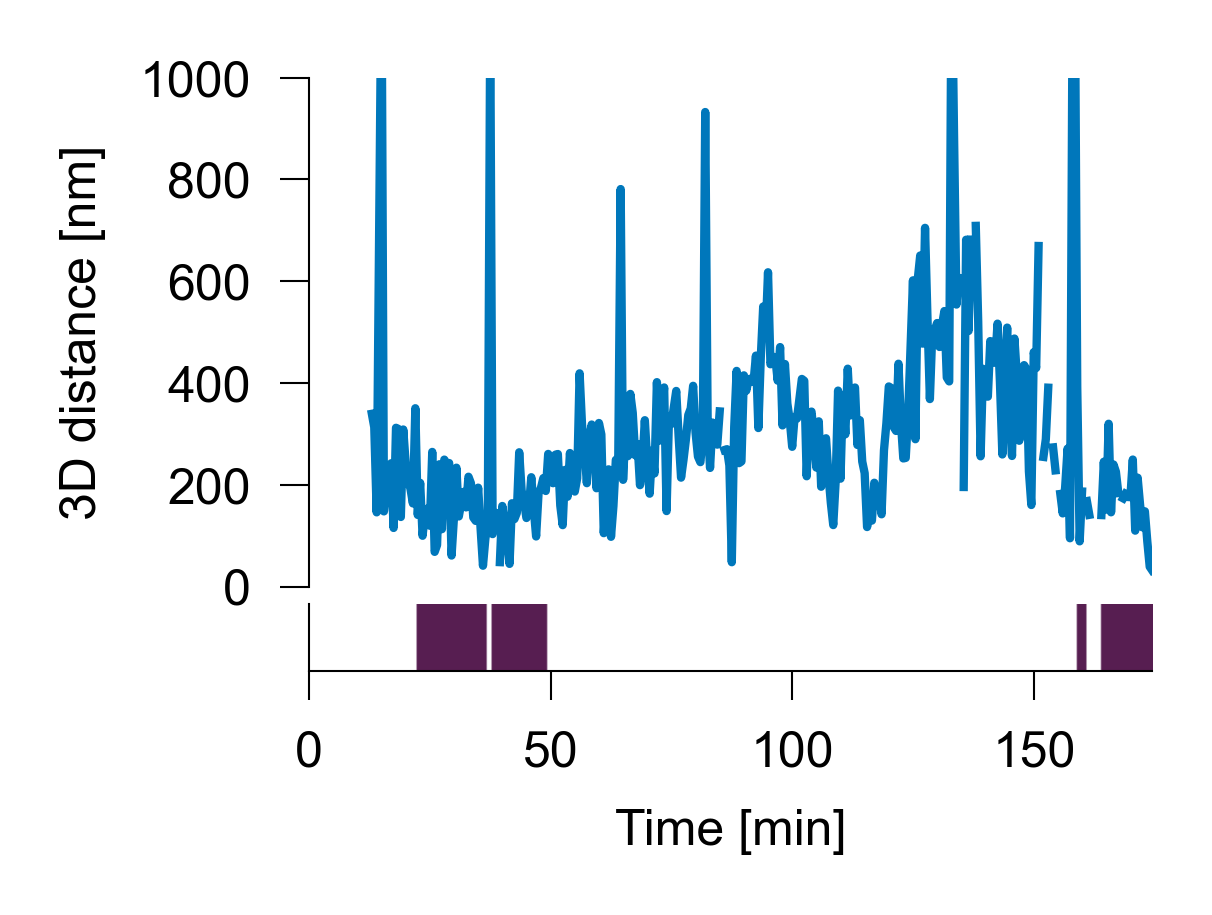

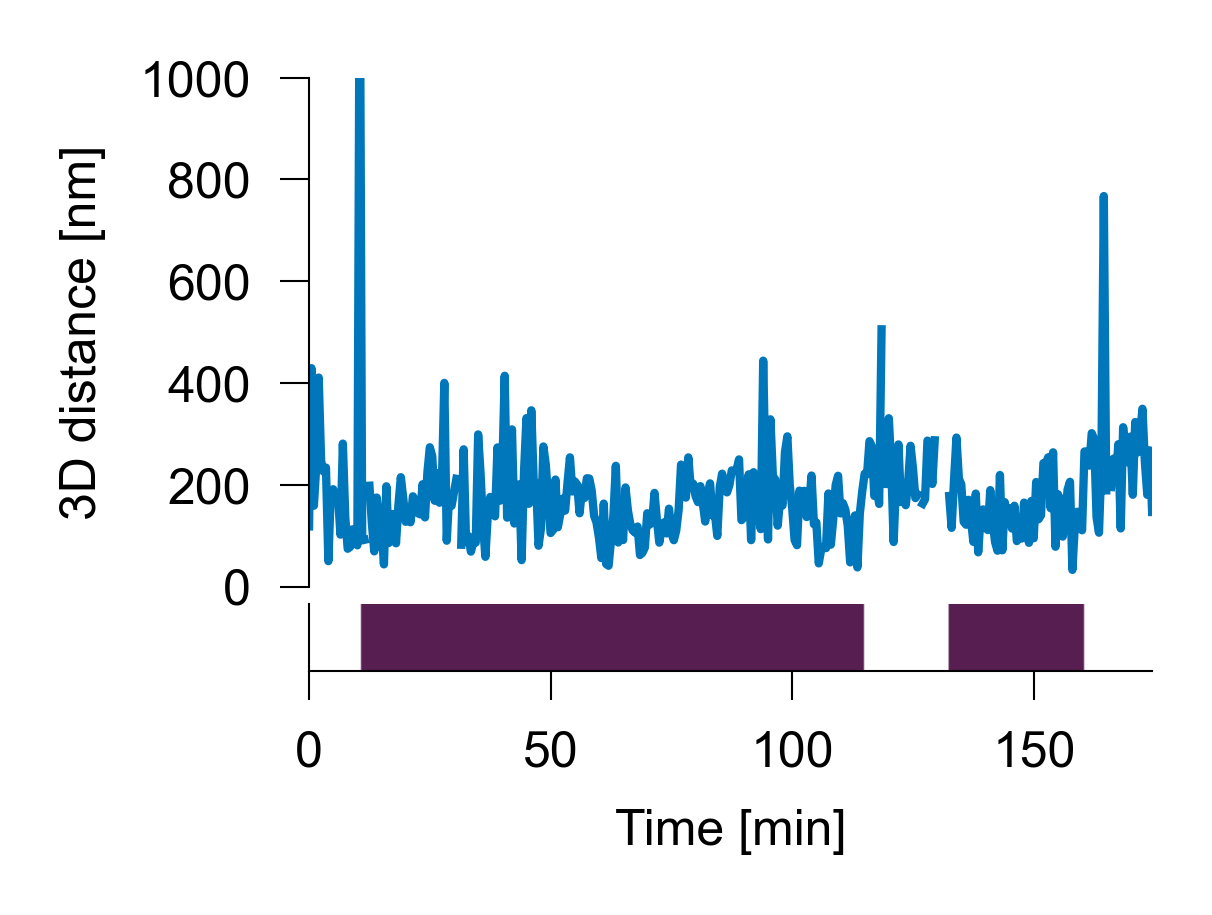

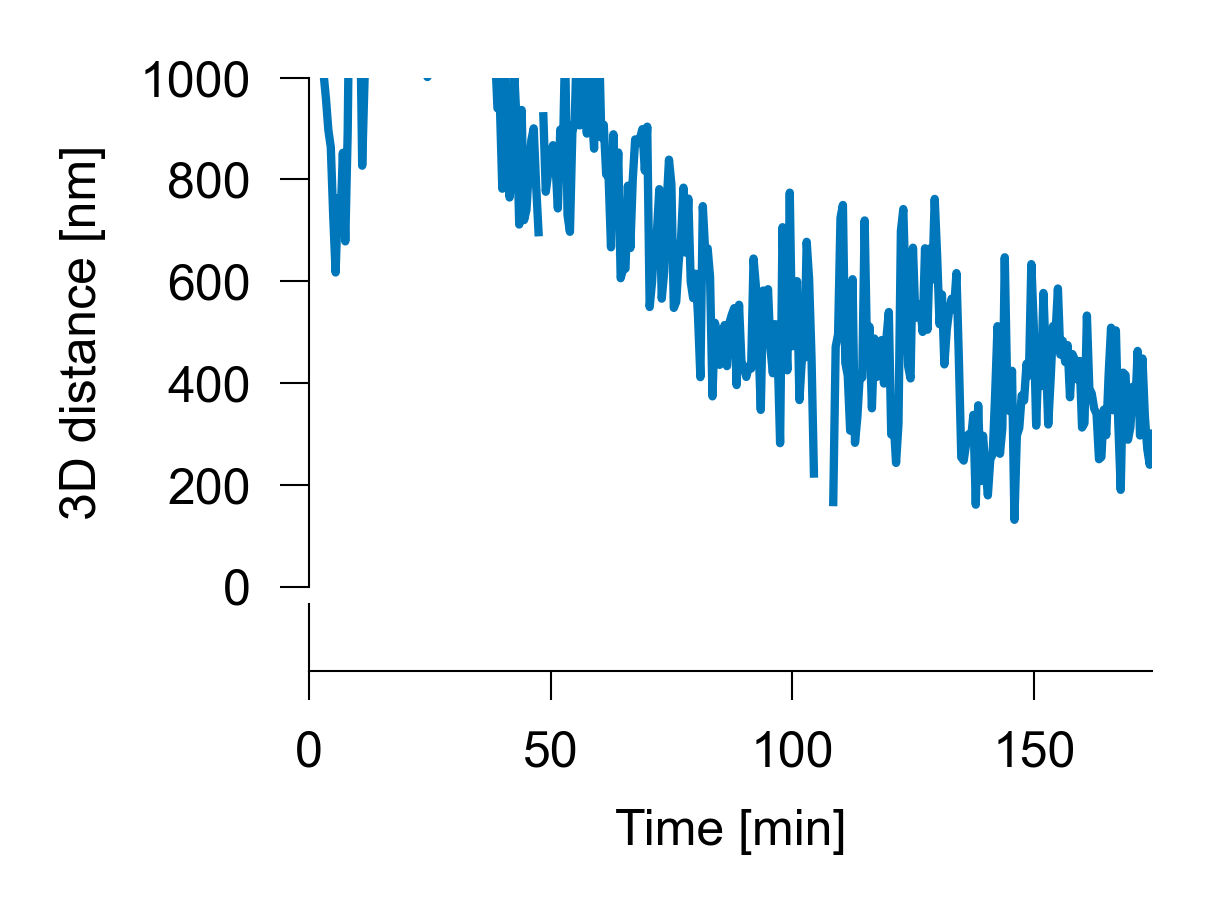

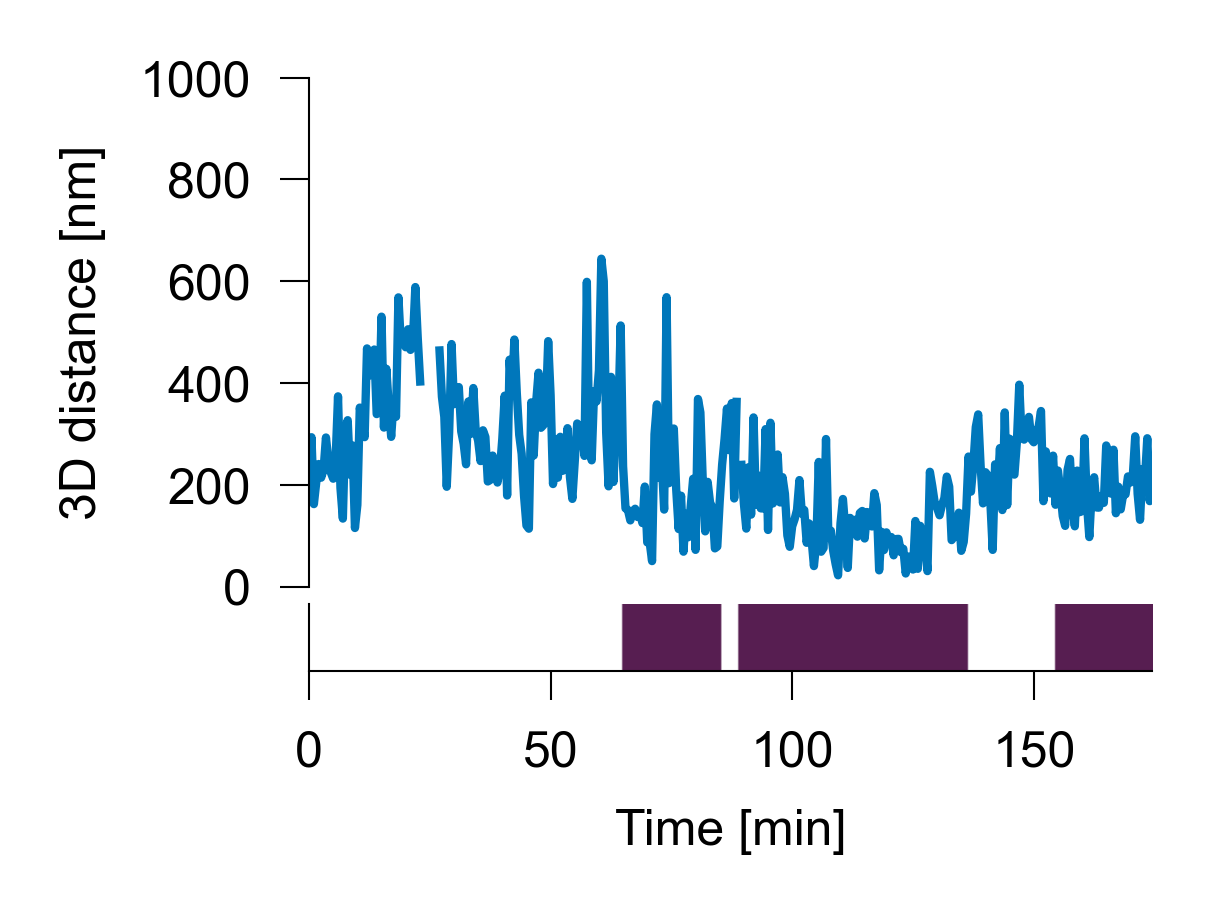

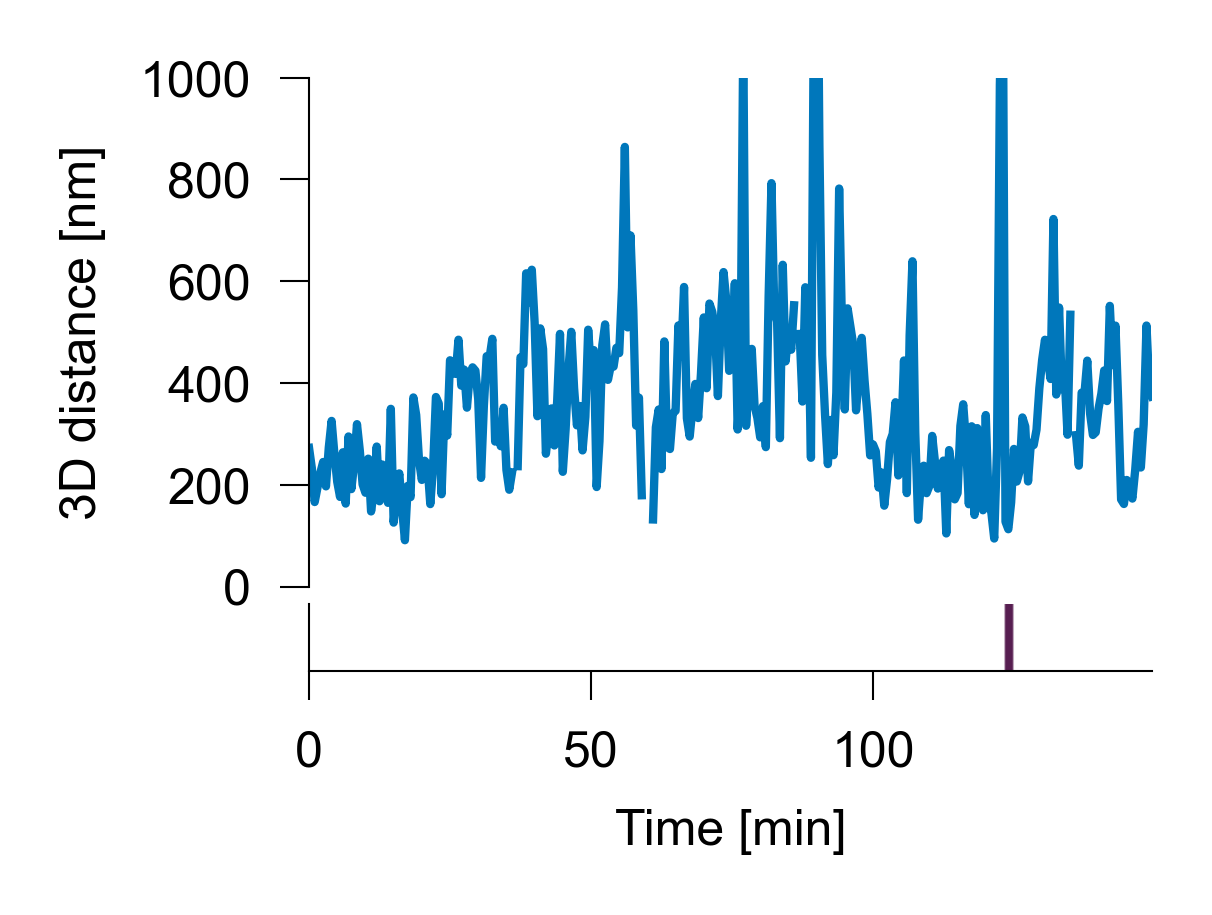

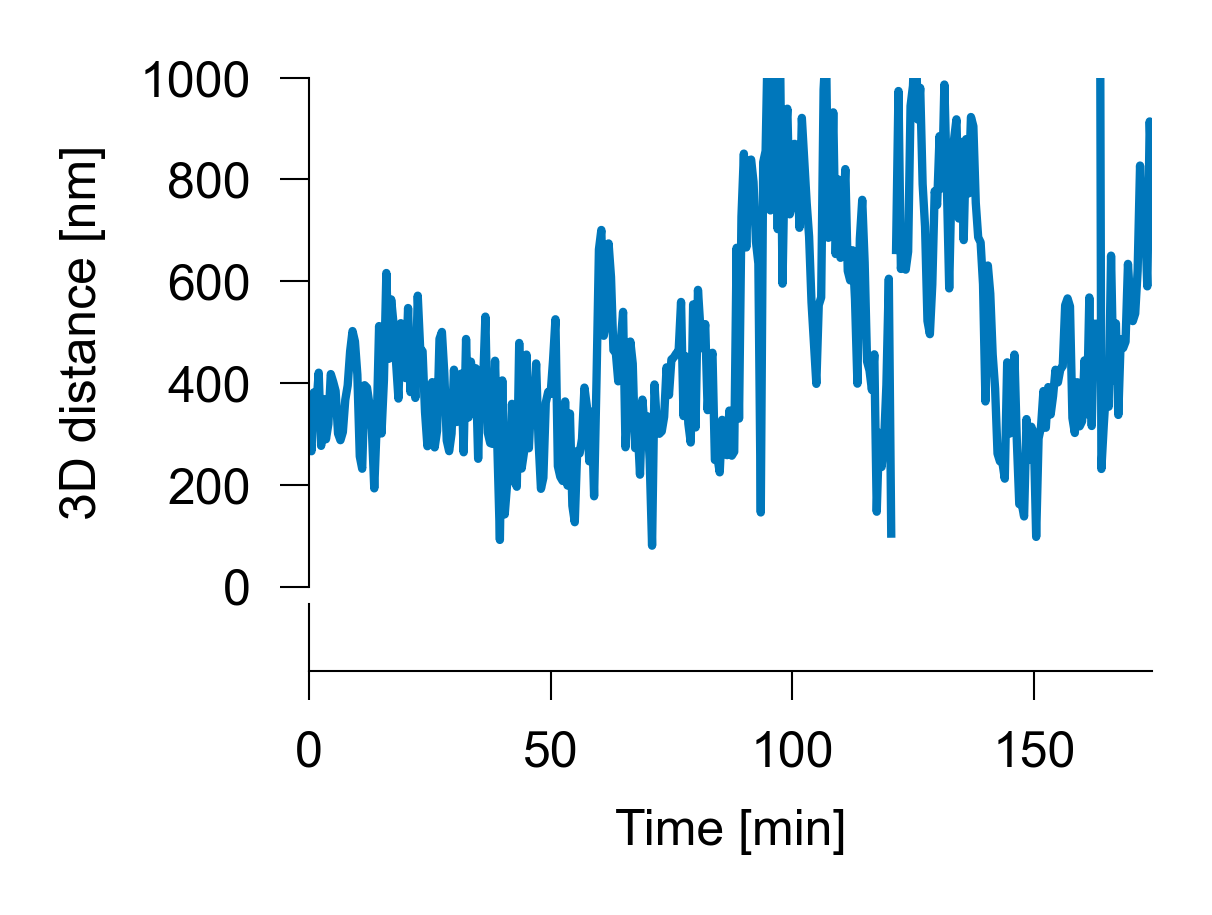

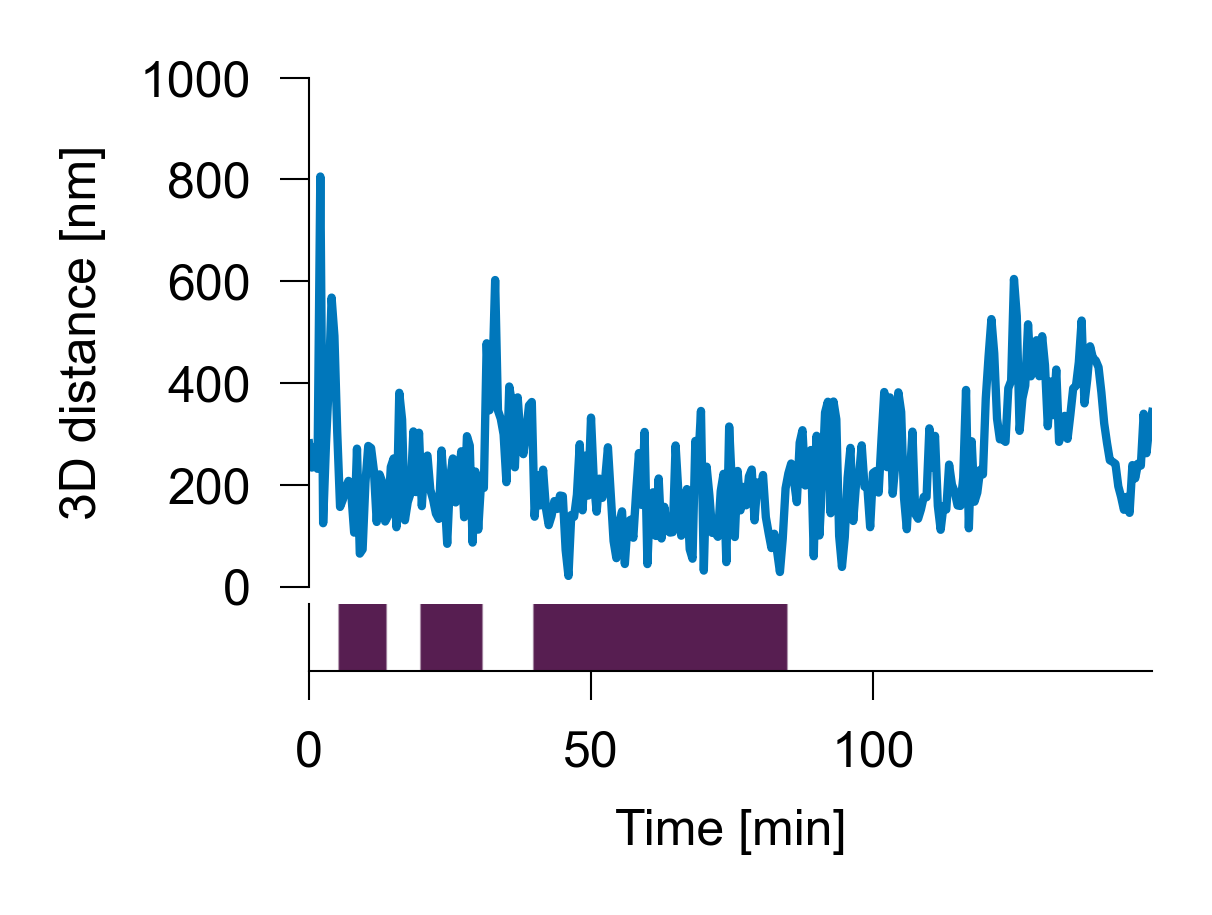

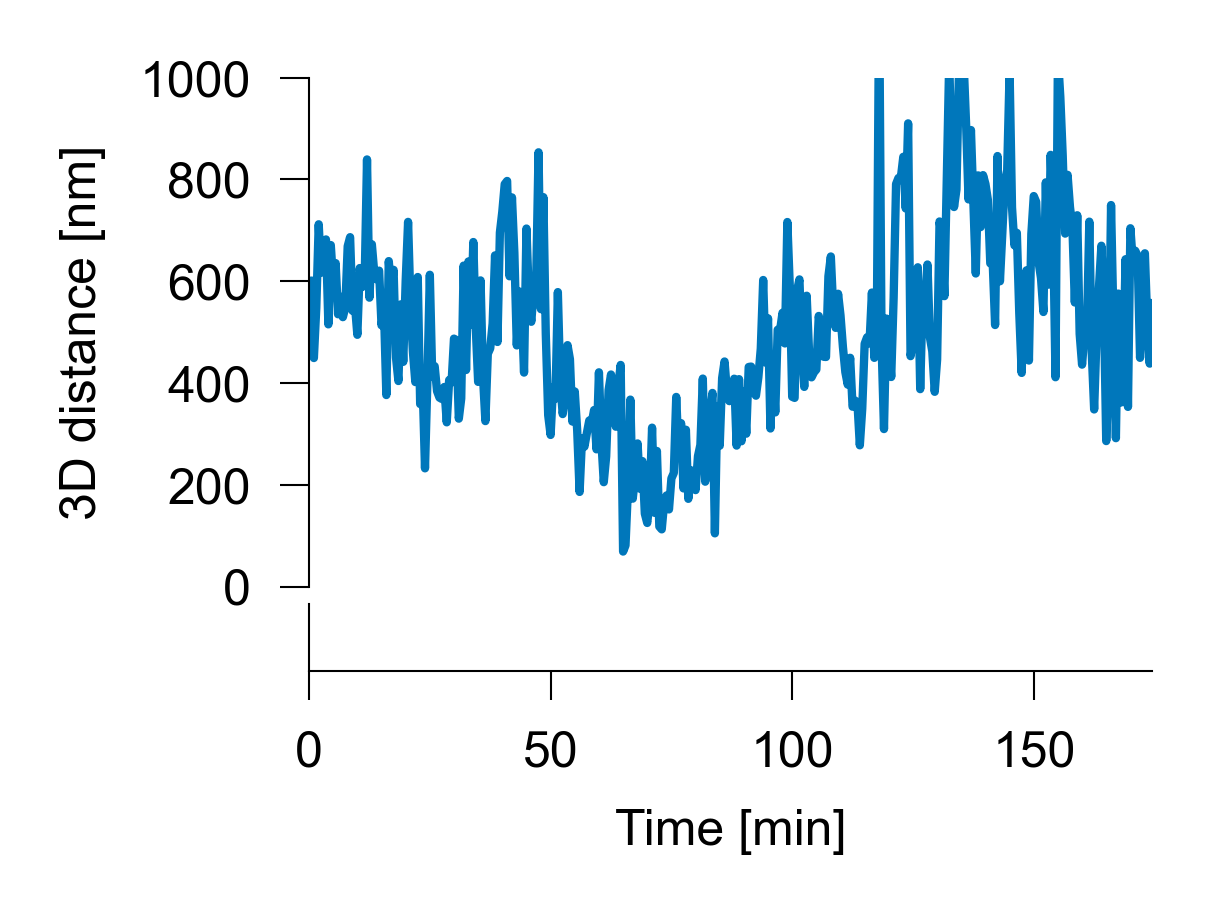

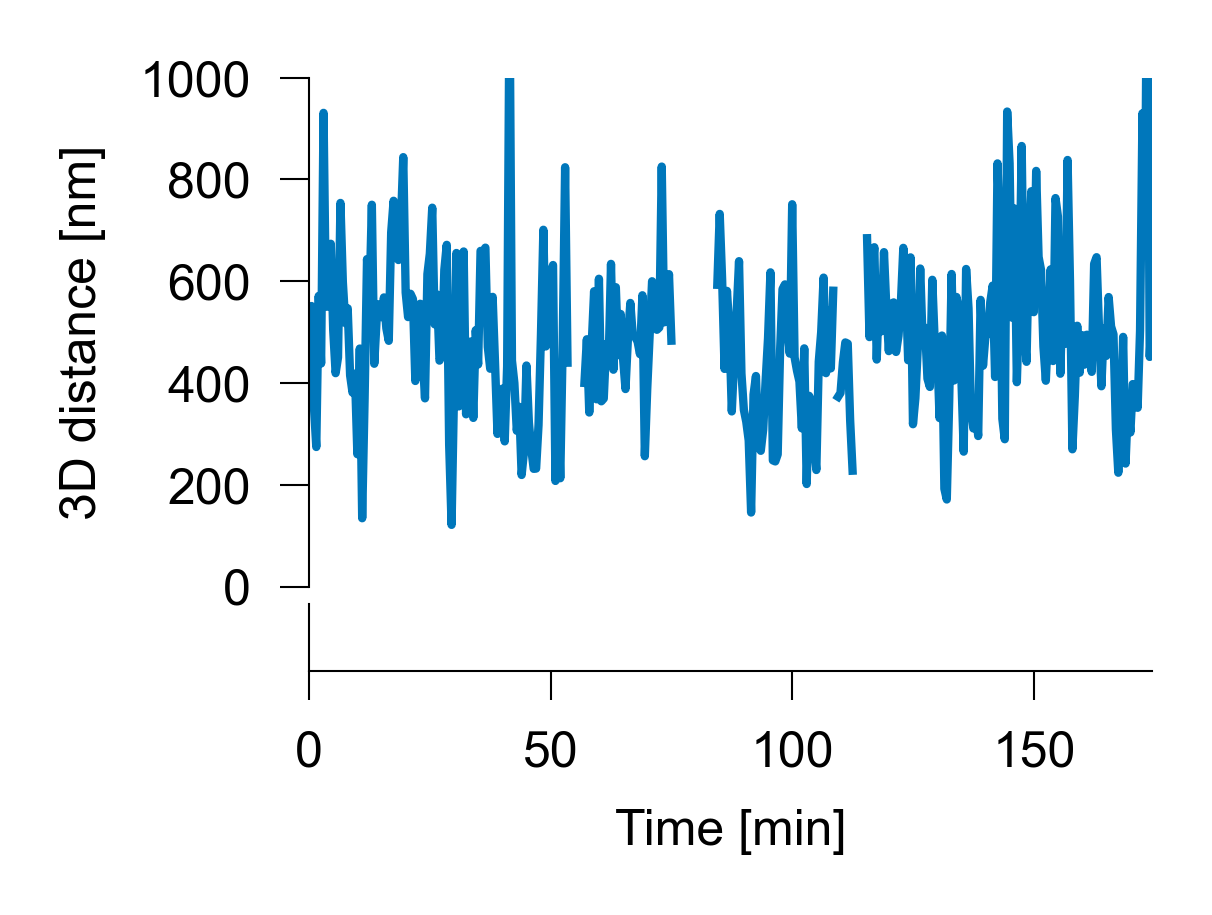

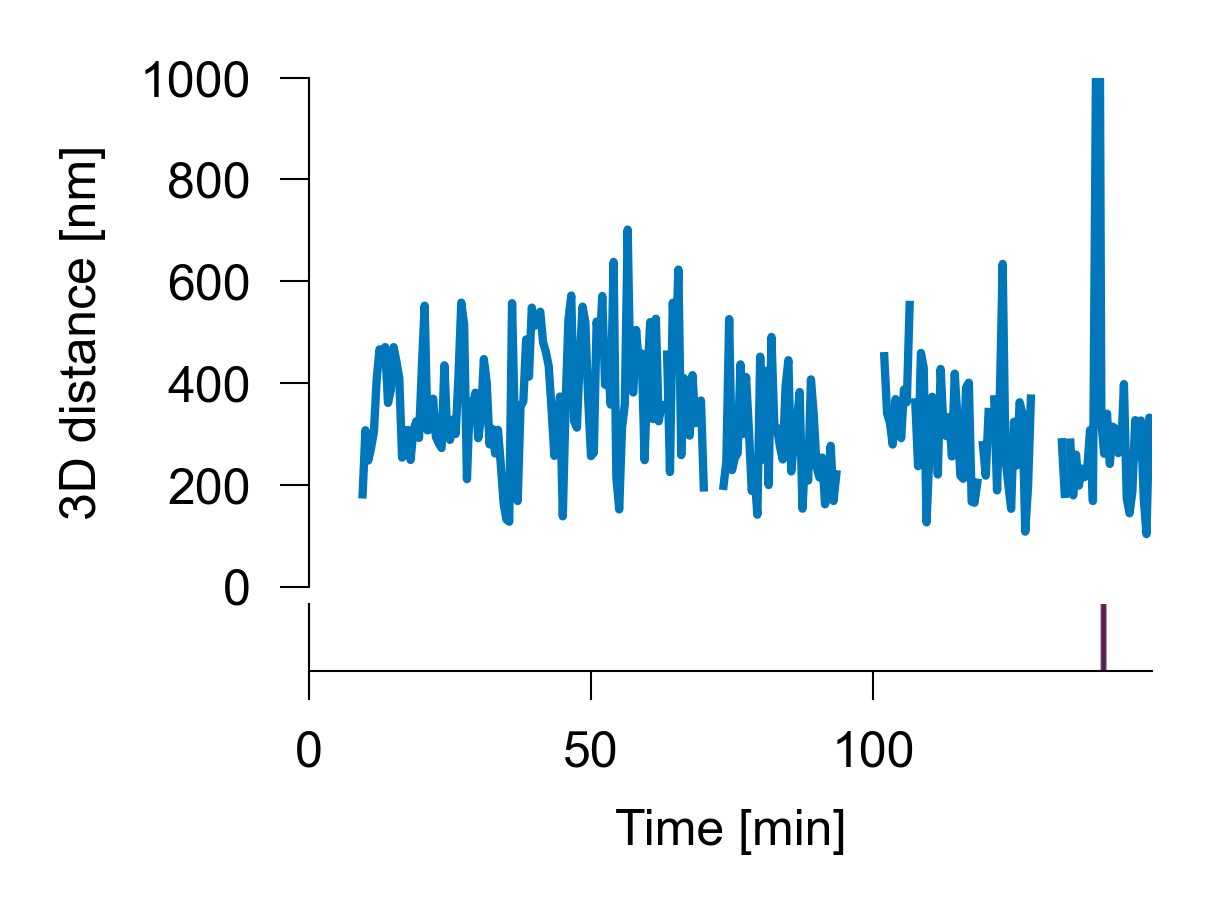

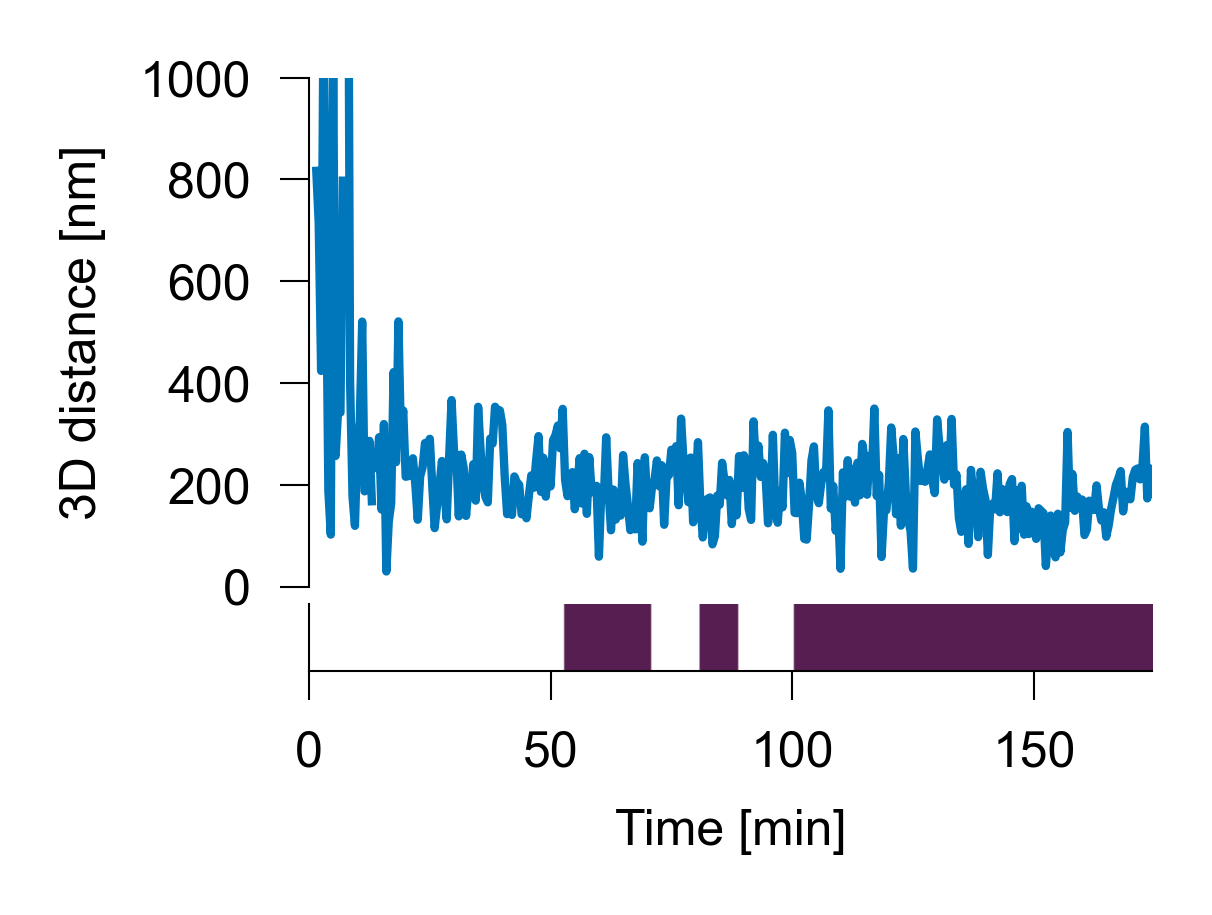

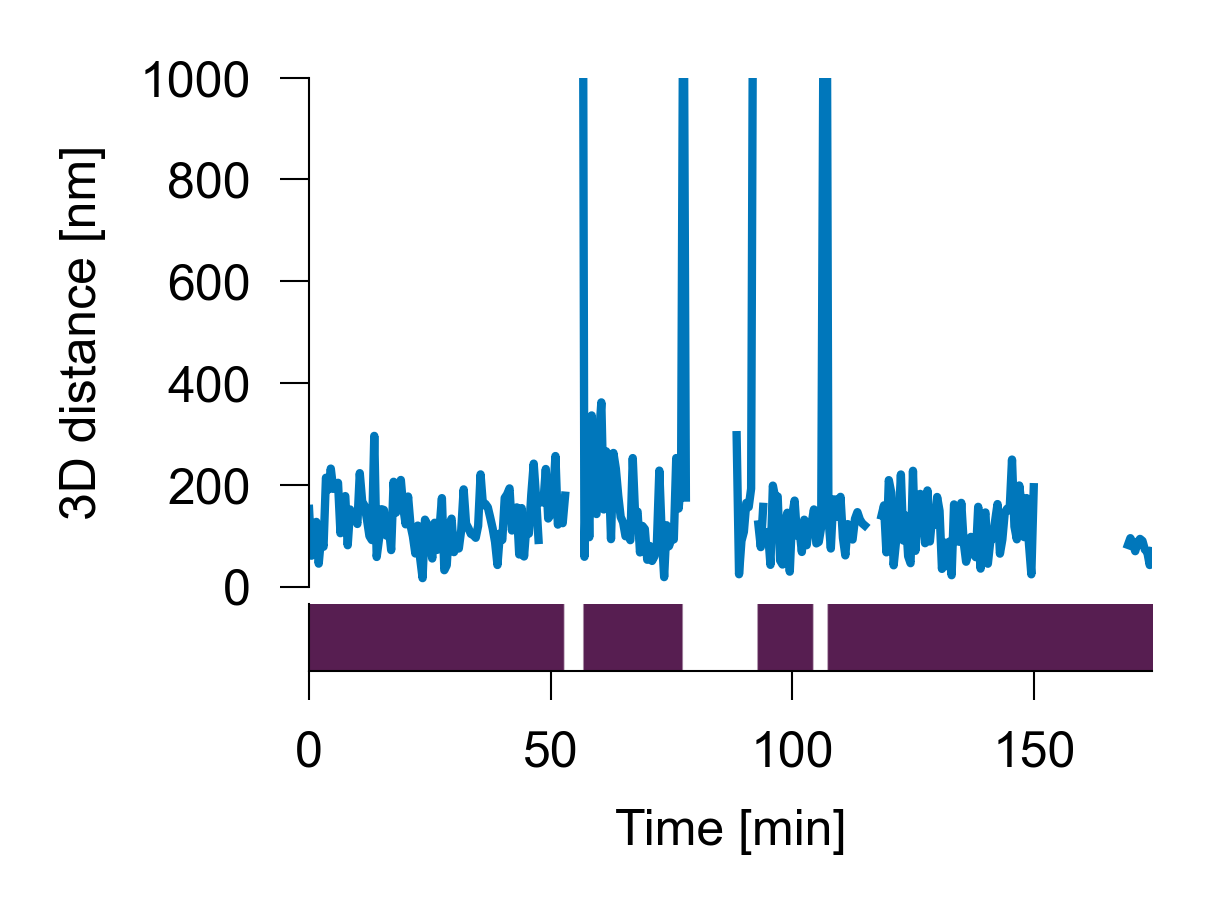

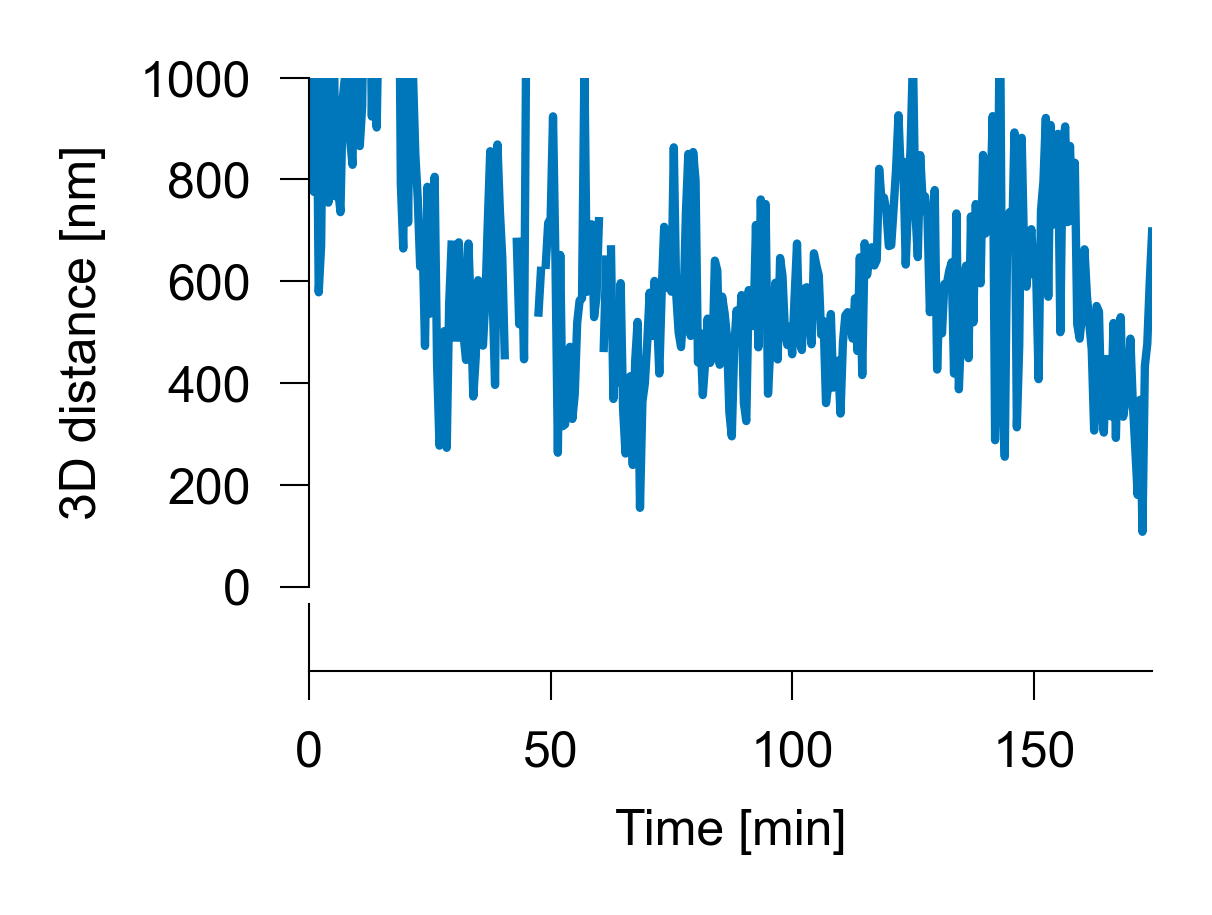

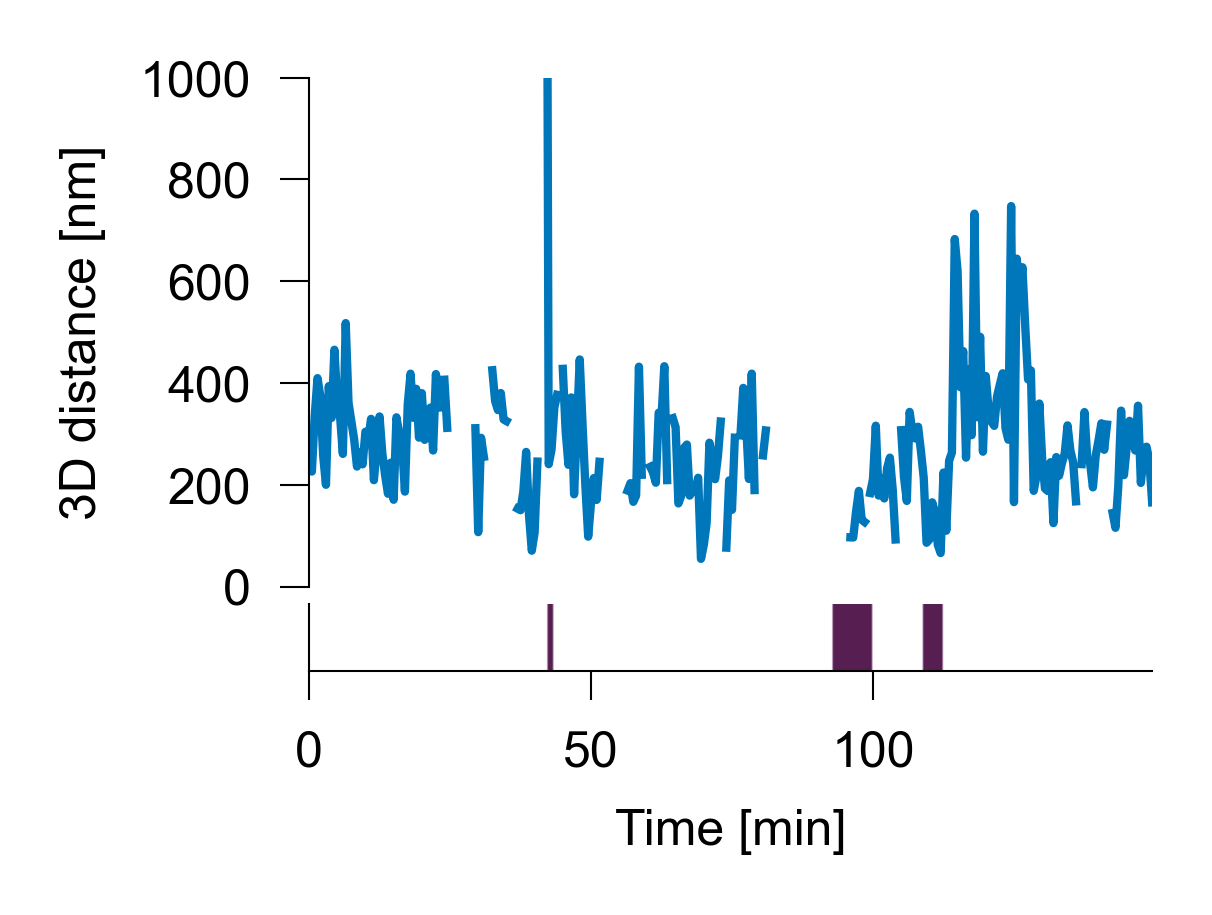

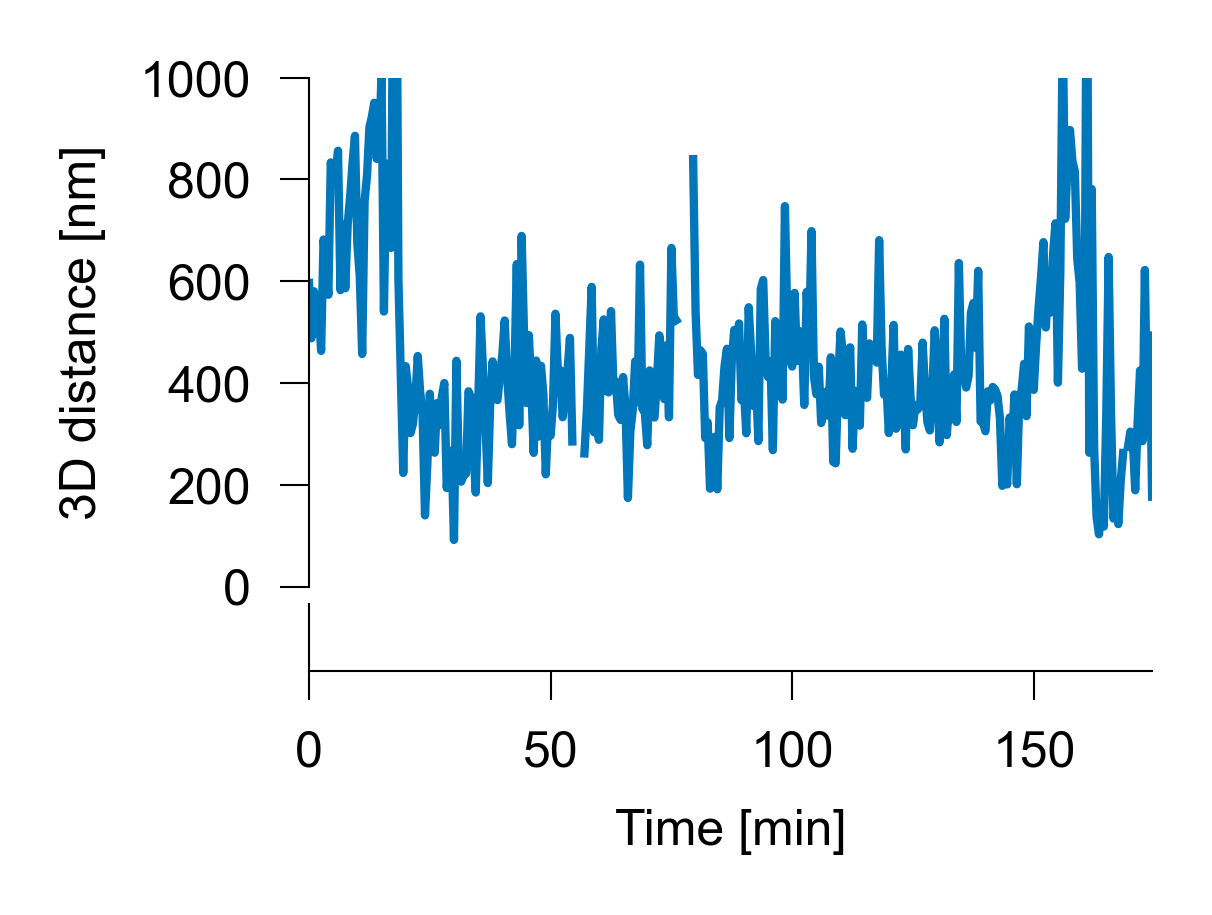

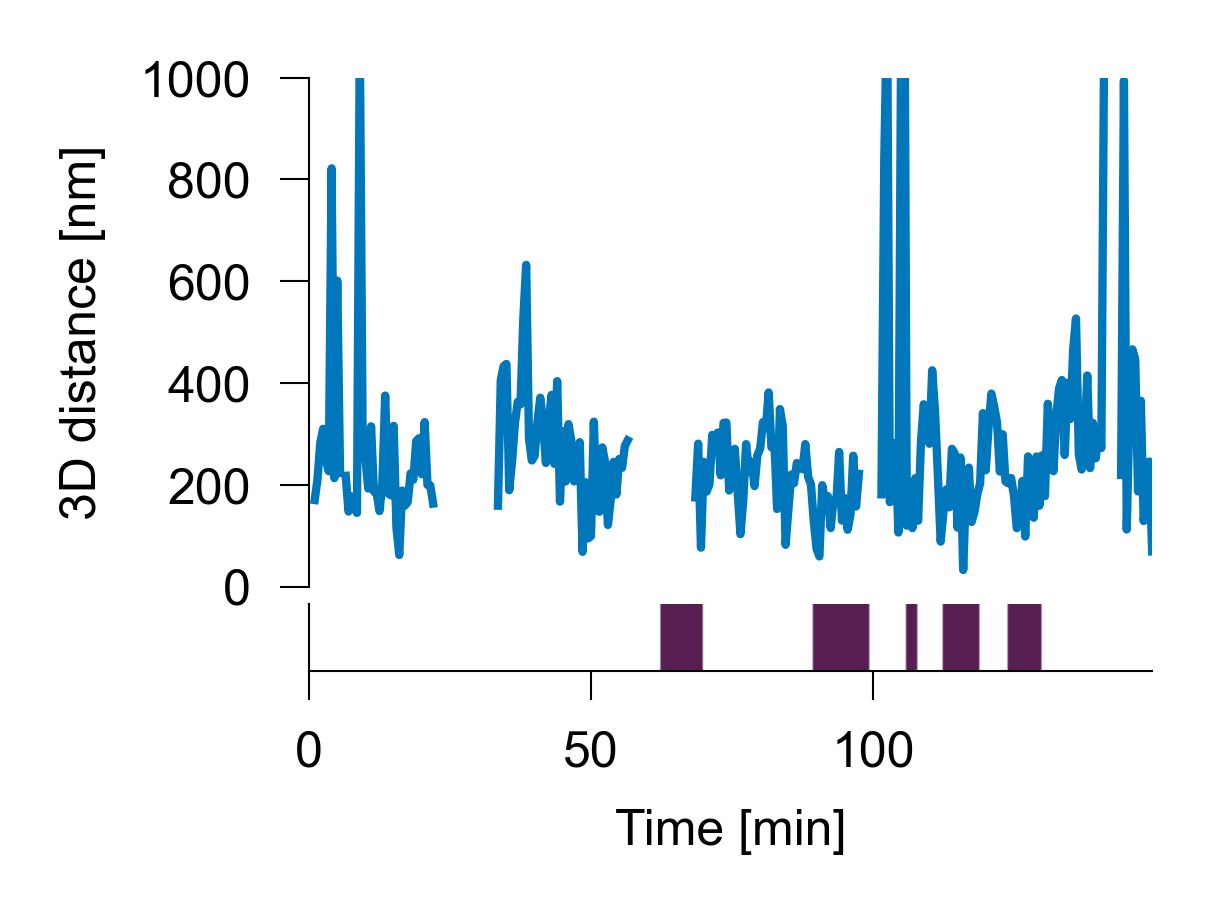

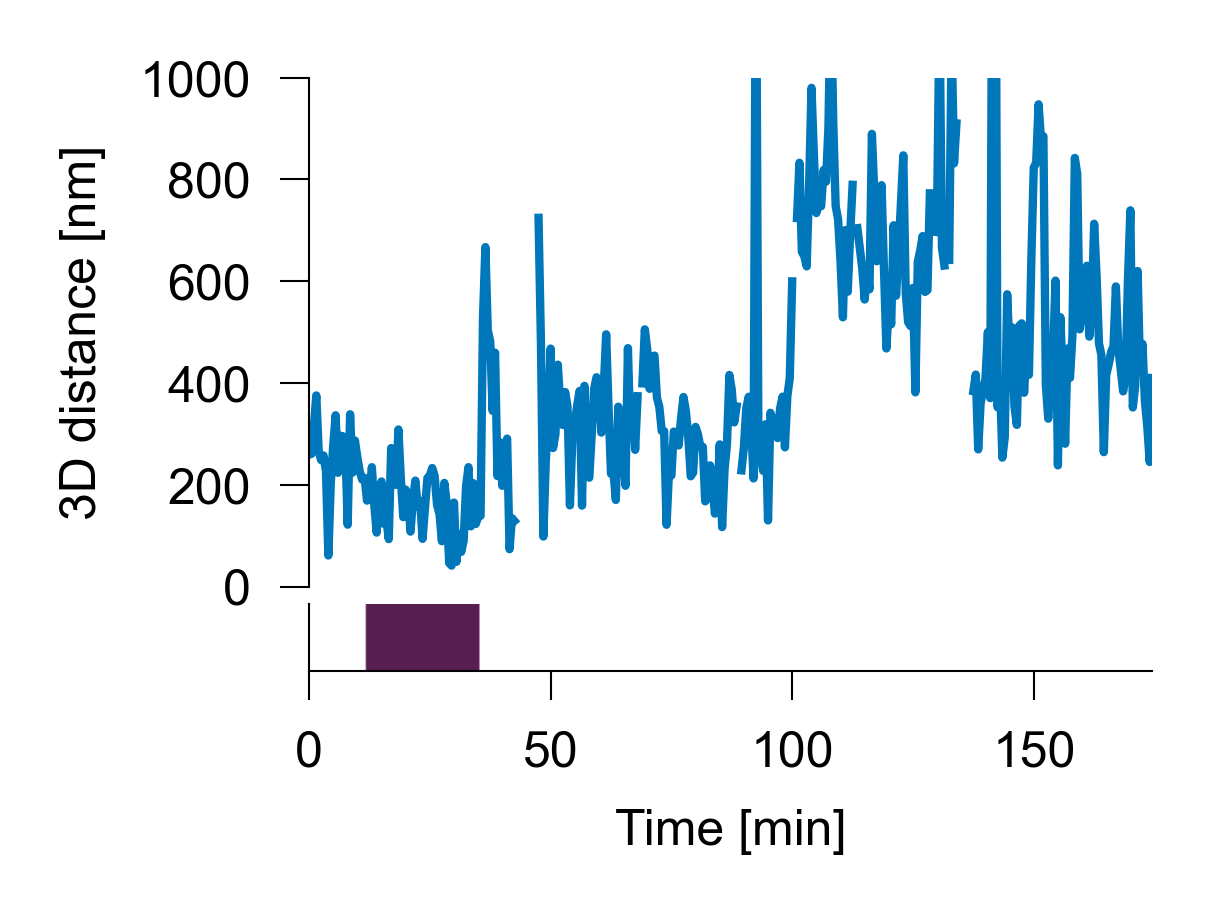

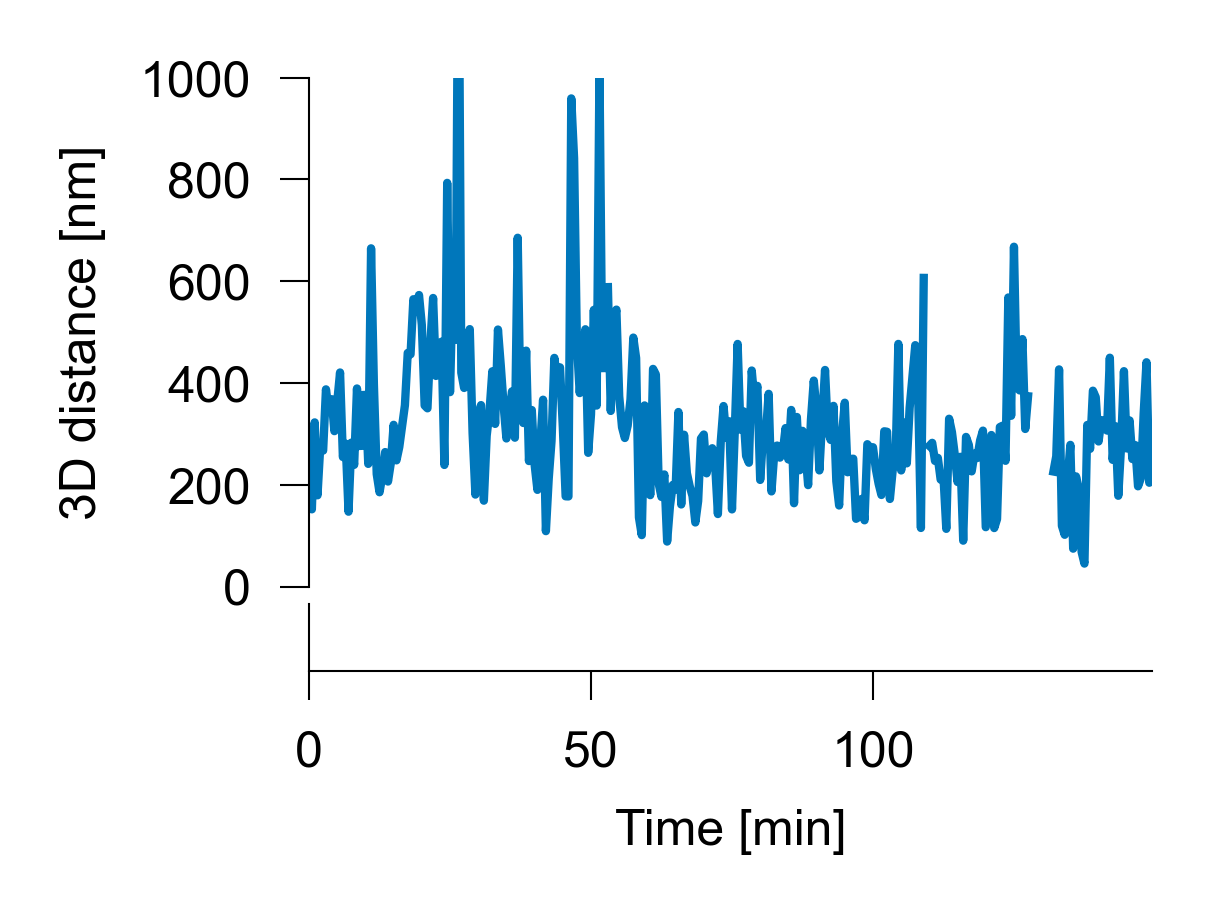

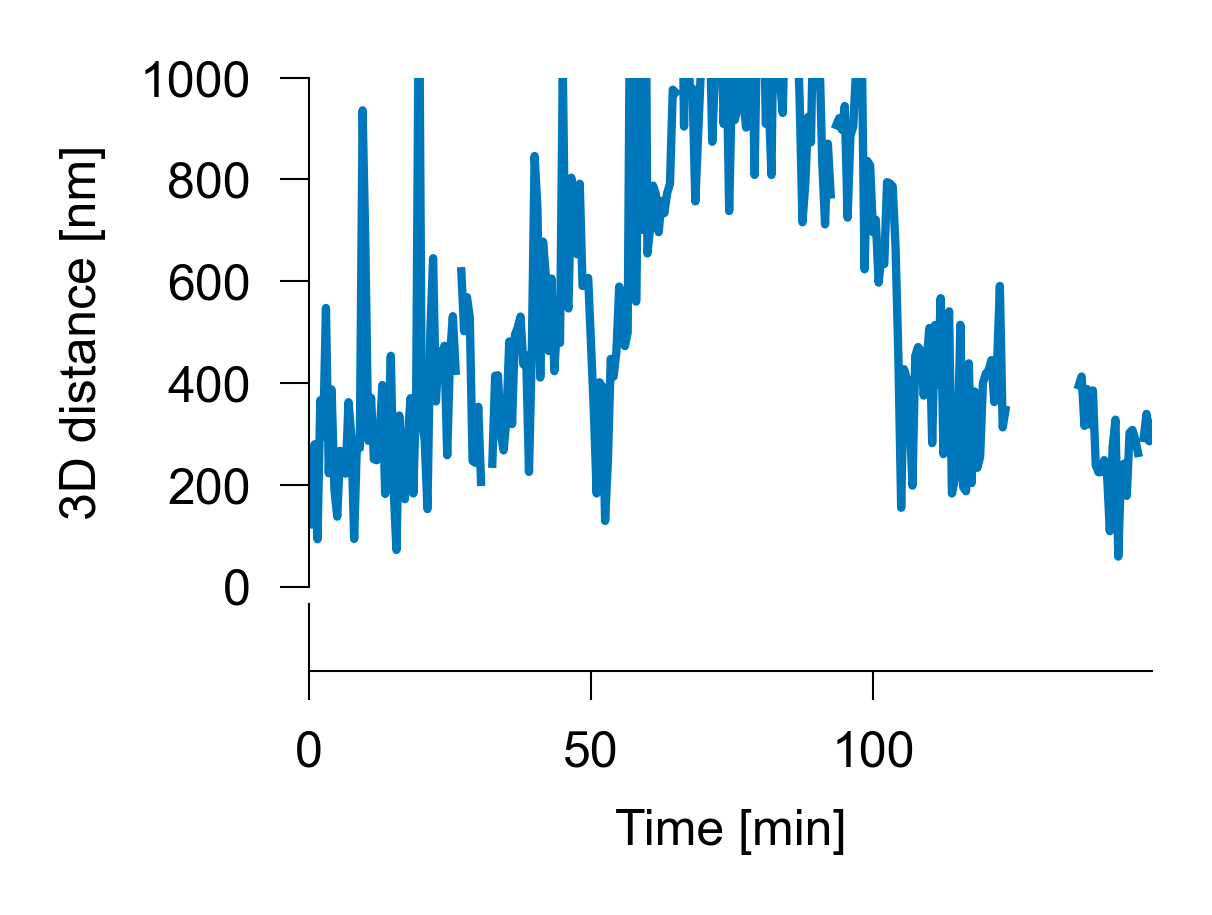

In [5]:
condition_names_to_plot = ['txn']*19
indices_to_plot = [1,3,32,35,36,40,45,47,52,90,133,140,164,171,196,261,267,289,292]
ymax_arr = [1000]*19

for condition, index, ymax in zip(condition_names_to_plot, indices_to_plot, ymax_arr):
    plot_track_with_profile(condition, index, ymin=0, ymax=ymax)
    plt.tight_layout()
    # plt.savefig(f'{figures_path}/example_traj_and_profile_{condition}_{index}.svg',transparent=True,bbox_inches='tight')

# Get looped fractions and lifetimes

In [3]:
def false_positive_correct(arr_inferred):
    '''Apply false positive correction to an array of BILD looping fraction estimates (%),
    as in  Fig. S11G of Gabriele et al. 2022, for ΔE=2: f_inferred = 1.34*f_true + 2.3.'''
    arr_true = (arr_inferred - 2.3)/1.34
    # arr_true = arr_inferred/1.34
    return arr_true

In [4]:
corrected_looped_frac_bootstrap_dists = {}

for condition in conditions:
    final_inferences = final_inferences_all[condition]

    # Algorithm 4 in Fbn2 SI
    num_trajs = len(final_inferences)
    bootstrap_dist = []

    for bootstrap_repeat in tqdm(range(1000)):
        rng = np.random.default_rng(bootstrap_repeat)
        looped_frames = 0
        total_frames = 0
        for repeat in range(num_trajs):
            i = rng.choice(np.arange(num_trajs))
            profile = final_inferences[i,:]
            profile = profile[~np.isnan(profile)]
            looped_frames += np.sum(profile==1)
            total_frames += np.sum(np.logical_or(profile==0,profile==1))
        percent_loop = looped_frames / total_frames * 100
        bootstrap_dist.append(percent_loop)

    bootstrap_dist = np.array(bootstrap_dist)

    bootstrap_dist = false_positive_correct(bootstrap_dist)
    corrected_looped_frac_bootstrap_dists[condition] = bootstrap_dist

100%|██████████| 1000/1000 [00:01<00:00, 752.62it/s]


In [21]:
for c in conditions:
	print((c,len(final_inferences_all[c])))

('unt', 261)
('dCtcf', 51)
('dRad21', 88)
('txn', 311)
('trp', 107)


In [34]:
len(corrected_looped_frac_bootstrap_dists['unt'])

1000

In [5]:
km_curves_with_CIs = {}
loop_lifetimes_medians_and_CIs = {}
lifetime_bootstrap_dists = {}

for condition in conditions:
    final_inferences = final_inferences_all[condition]
    
    m, x, y, y_CI_lower, y_CI_upper = km_median_lifetime(final_inferences, return_ci=True)
    x = x*30/60  # convert to minutes

    m, m_std, m_ci, m_dist = km_median_bootstrap(final_inferences, n_boot=1000, seed=0)
    m *= 30/60
    m_std *= 30/60  # don't need this for plots
    m_ci = (m_ci[0]*30/60, m_ci[1]*30/60)

    km_curves_with_CIs[condition] = (x, y, y_CI_lower, y_CI_upper)
    loop_lifetimes_medians_and_CIs[condition] = (m, m_ci)
    lifetime_bootstrap_dists[condition] = m_dist


In [ ]:
km_curves_with_CIs

In [6]:
loop_lifetimes_medians_and_CIs

{'unt': (9.5, (8.6125, 12.3875)),
 'dCtcf': (7.5, (4.5, 12.325000000000001)),
 'dRad21': (2.0, (1.5, 3.5)),
 'txn': (9.0, (8.0, 10.3875)),
 'trp': (8.0, (6.5, 8.5))}

# Panel d: Rescaled Kaplan-Meier curves

7.082456418467595
7.252387306693133
8.382833514360351


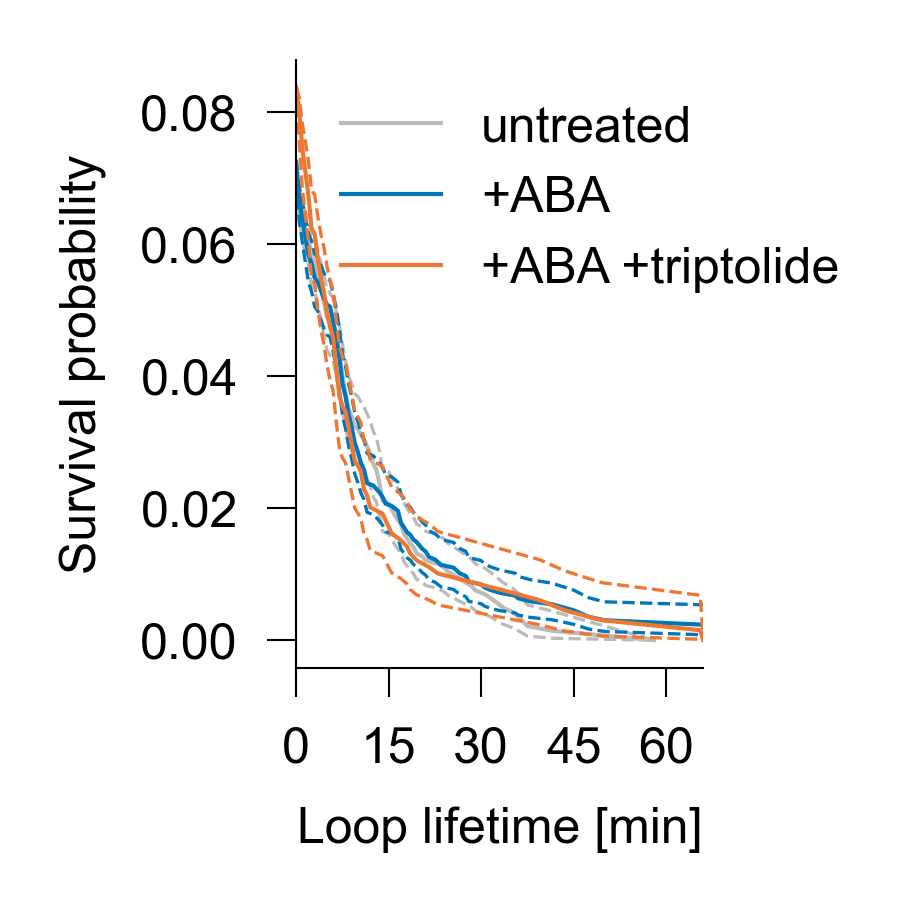

In [6]:
fig, ax = plt.subplots(figsize=(1.25, 1.5), dpi=300, frameon=False)
conditions_to_plot = ['unt','txn','trp']
for condition in conditions_to_plot:
    looped_frac = np.mean(corrected_looped_frac_bootstrap_dists[condition])
    print(looped_frac)
    x, y, y_CI_lower, y_CI_upper = km_curves_with_CIs[condition]

    # rescale by looped fraction
    y_rescaled = y * looped_frac/100
    y_CI_lower_rescaled = y_CI_lower * looped_frac/100
    y_CI_upper_rescaled = y_CI_upper * looped_frac/100

    ax.plot(x, y_rescaled, color=colors_dict[condition], linewidth=0.5,label=names_dict[condition])
    ax.plot(x, y_CI_lower_rescaled, color=colors_dict[condition], linestyle='--', linewidth=0.4)
    ax.plot(x, y_CI_upper_rescaled, color=colors_dict[condition], linestyle='--', linewidth=0.4)

ax.set_ylabel('Survival probability')
ax.set_xlabel('Loop lifetime [min]');
ax.set_xticks([0,15,30,45,60])
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlim(0, np.max(x))
ax.legend()
# ax.set_ylim(0, 0.095)

plt.tight_layout()
plt.savefig(f'{figures_path}/rescaled_KM_curves.svg',transparent=True,bbox_inches='tight')


# Panel e: Looped fraction

Condition: unt, mean: 7.07940205381357, CI_lower: 5.318289254739814, CI_upper: 8.806922378705384
Condition: txn, mean: 7.2817094912847455, CI_lower: 5.394820993286094, CI_upper: 9.26954515181762
Condition: trp, mean: 8.485683233330906, CI_lower: 5.538511147963884, CI_upper: 11.529150681862728


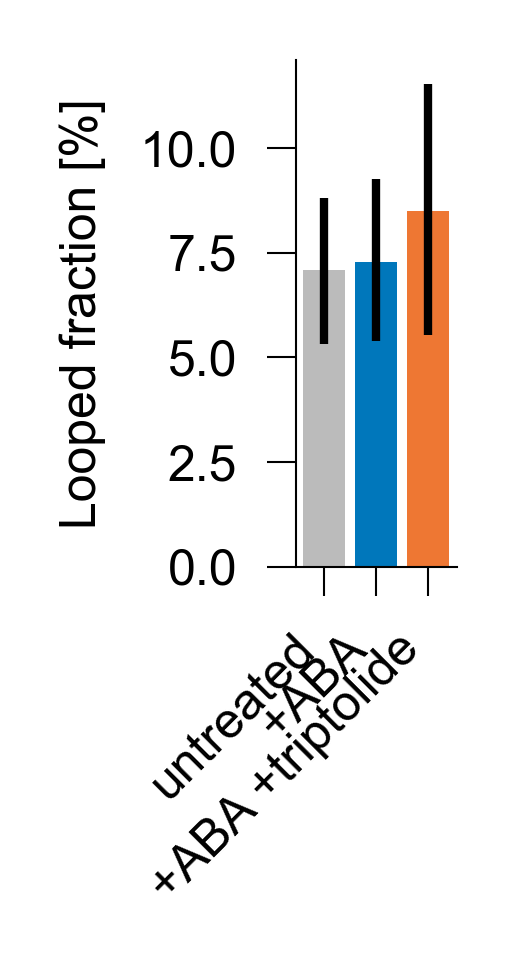

In [ ]:
fig, ax = plt.subplots(figsize=(0.84, 1.6), dpi=300, frameon=False)
conditions_to_plot = ['unt','txn','trp']
x = 0
for condition in conditions_to_plot:
    y = np.mean(corrected_looped_frac_bootstrap_dists[condition])
    y_CI_lower = np.quantile(corrected_looped_frac_bootstrap_dists[condition], 0.025)
    y_CI_upper = np.quantile(corrected_looped_frac_bootstrap_dists[condition], 0.975)
    ax.bar(x=[x], height=[y], color=colors_dict[condition], yerr=[[y-y_CI_lower], [y_CI_upper-y]])
    x+=1
    print(f'Condition: {condition}, mean: {y}, CI_lower: {y_CI_lower}, CI_upper: {y_CI_upper}')

ax.set_xticks([0,1,2], [names_dict[condition] for condition in conditions_to_plot], rotation=45,ha='right')
ax.set_ylabel('Looped fraction [%]')
ax.set_yticks([0,2.5,5,7.5,10])
# ax.set_ylim(0, 11);
ax.spines[['top', 'right']].set_visible(False);

plt.tight_layout();
# plt.savefig(f'{figures_path}/looped_fraction.svg',transparent=True,bbox_inches='tight')


In [49]:
frac_stats = {}
for comparison in itertools.combinations(conditions_to_plot,2):
    name = f'{comparison[0]} vs {comparison[1]}'
    # stat = stats.ttest_ind_from_stats(np.mean(corrected_looped_frac_bootstrap_dists[comparison[0]]),
    #                                   np.std(corrected_looped_frac_bootstrap_dists[comparison[0]],ddof=1),
    #                                   len(final_inferences_all[comparison[0]]),
    #                                   np.mean(corrected_looped_frac_bootstrap_dists[comparison[1]]),
    #                                   np.std(corrected_looped_frac_bootstrap_dists[comparison[1]],ddof=1),
    #                                   len(final_inferences_all[comparison[1]]),equal_var=False).pvalue*len(conditions_to_plot)
    # stat = stats.ttest_ind_from_stats(np.mean(corrected_looped_frac_bootstrap_dists[comparison[0]]),
    #                                   np.std(corrected_looped_frac_bootstrap_dists[comparison[0]],ddof=1),
    #                                   2,
    #                                   np.mean(corrected_looped_frac_bootstrap_dists[comparison[1]]),
    #                                   np.std(corrected_looped_frac_bootstrap_dists[comparison[1]],ddof=1),
    #                                   2,equal_var=False).pvalue*len(conditions_to_plot)
    # frac_stats[name] = stat
    stat = (np.mean(corrected_looped_frac_bootstrap_dists[comparison[0]])-
            np.mean(corrected_looped_frac_bootstrap_dists[comparison[1]]))/np.sqrt(
                np.std(corrected_looped_frac_bootstrap_dists[comparison[0]],ddof=1)**2+
                np.std(corrected_looped_frac_bootstrap_dists[comparison[1]],ddof=1)**2
            )
    pval = np.min(np.array([stats.t.sf(np.abs(stat),len(final_inferences_all[comparison[0]])+len(final_inferences_all[comparison[1]])-2)*2*3,1]))
    frac_stats[name] = pval
frac_stats

{'unt vs txn': 1.0, 'unt vs trp': 1.0, 'txn vs trp': 1.0}

In [45]:
unt_mean = np.mean(corrected_looped_frac_bootstrap_dists['unt'])
unt_std = np.std(corrected_looped_frac_bootstrap_dists['unt'],ddof=1)
txn_mean = np.mean(corrected_looped_frac_bootstrap_dists['txn'])
txn_std = np.std(corrected_looped_frac_bootstrap_dists['txn'],ddof=1)
trp_mean = np.mean(corrected_looped_frac_bootstrap_dists['trp'])
trp_std = np.std(corrected_looped_frac_bootstrap_dists['trp'],ddof=1)
print((unt_mean,unt_std))
print((txn_mean,txn_std))
print((trp_mean,trp_std))

(7.07940205381357, 0.9174835502838565)
(7.2817094912847455, 1.0215749551775497)
(8.485683233330906, 1.5201010059910487)


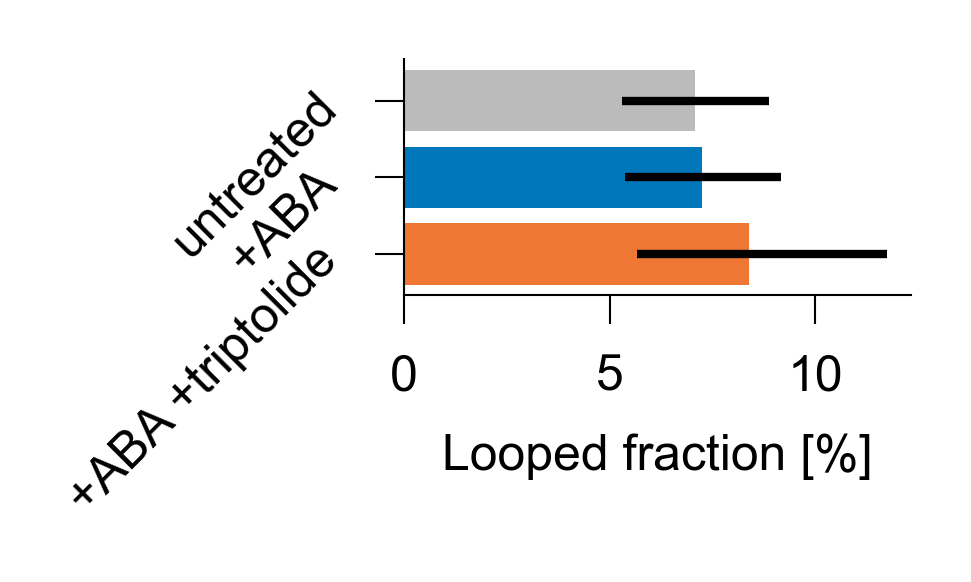

In [11]:
fig, ax = plt.subplots(figsize=(1.6, 0.9), dpi=300, frameon=False)
conditions_to_plot = ['unt','txn','trp']
y = 2
for condition in conditions_to_plot:
    x = np.mean(corrected_looped_frac_bootstrap_dists[condition])
    x_CI_lower = np.quantile(corrected_looped_frac_bootstrap_dists[condition], 0.025)
    x_CI_upper = np.quantile(corrected_looped_frac_bootstrap_dists[condition], 0.975)
    ax.barh(width=[x], y=[y], color=colors_dict[condition], xerr=[[x-x_CI_lower], [x_CI_upper-x]])
    y-=1

ax.set_yticks([2,1,0], [names_dict[condition] for condition in conditions_to_plot], rotation=45,ha='right')
ax.set_xlabel('Looped fraction [%]')
# ax.set_ylim(0, 11);
ax.spines[['top', 'right']].set_visible(False);

plt.tight_layout();
plt.savefig(f'{figures_path}/looped_fraction_horizontal.svg',transparent=True,bbox_inches='tight')

# Panel f: Loop lifetimes

Condition: unt, mean: 8.5, CI_lower: 7.5, CI_upper: 12.0
Condition: txn, mean: 8.5, CI_lower: 7.5, CI_upper: 9.5
Condition: trp, mean: 6.5, CI_lower: 5.0, CI_upper: 8.5


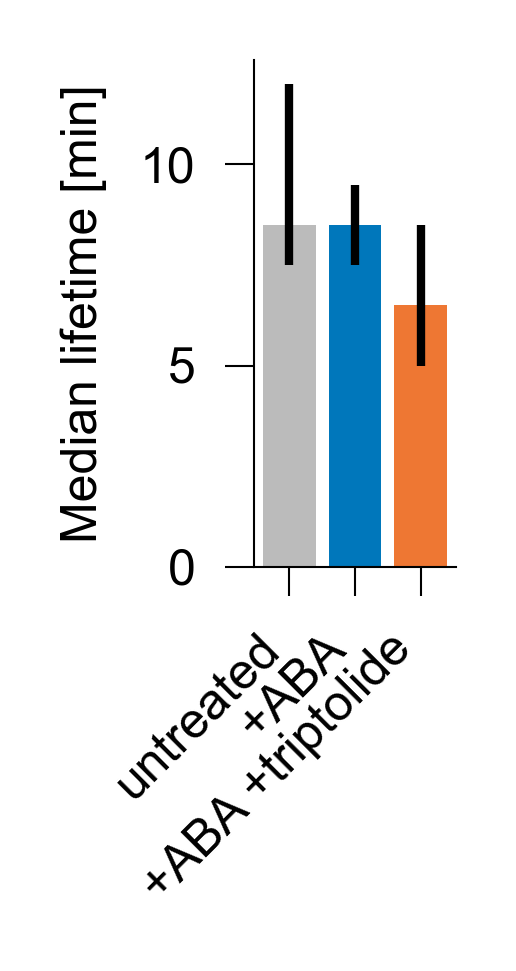

In [24]:
fig, ax = plt.subplots(figsize=(0.84,1.6), dpi=300, frameon=False)

x= 0
for condition in conditions_to_plot:
    m, m_ci = loop_lifetimes_medians_and_CIs[condition]
    y = m
    ax.bar(x=[x], height=[y], color=colors_dict[condition], yerr=[[m-m_ci[0]], [m_ci[1]-m]])
    x+=1
    print(f'Condition: {condition}, mean: {m}, CI_lower: {m_ci[0]}, CI_upper: {m_ci[1]}')

ax.set_xticks([0,1,2], [names_dict[condition] for condition in conditions_to_plot],rotation=45,ha='right')
ax.set_ylabel('Median lifetime [min]')

# ax.set_ylim(0, 13);
ax.spines[['top', 'right']].set_visible(False);
fig.align_xlabels()
plt.tight_layout()
# plt.savefig(f'{figures_path}/loop_lifetimes.svg',transparent=True,bbox_inches='tight')

In [50]:
life_stats = {}
for comparison in itertools.combinations(conditions_to_plot,2):
    name = f'{comparison[0]} vs {comparison[1]}'
    # stat = stats.ttest_ind_from_stats(np.mean(lifetime_bootstrap_dists[comparison[0]]),
    #                                       np.std(lifetime_bootstrap_dists[comparison[0]],ddof=1),
    #                                       len(final_inferences_all[comparison[0]]),
    #                                       np.mean(lifetime_bootstrap_dists[comparison[1]]),
    #                                       np.std(lifetime_bootstrap_dists[comparison[1]],ddof=1),
    #                                       len(final_inferences_all[comparison[1]]),equal_var=False).pvalue*3
    # stat = stats.ttest_ind(lifetime_bootstrap_dists[comparison[0]],
    #                           lifetime_bootstrap_dists[comparison[1]],
    #                           equal_var=False).pvalue*3
    stat = (np.mean(lifetime_bootstrap_dists[comparison[0]])-
            np.mean(lifetime_bootstrap_dists[comparison[1]]))/np.sqrt(
                np.std(lifetime_bootstrap_dists[comparison[0]],ddof=1)**2+
                np.std(lifetime_bootstrap_dists[comparison[1]],ddof=1)**2
            )
    pval = np.min(np.array([stats.t.sf(np.abs(stat),len(final_inferences_all[comparison[0]])+len(final_inferences_all[comparison[1]])-2)*2*3,1]))
    life_stats[name] = pval
life_stats

{'unt vs txn': 1.0,
 'unt vs trp': 0.19229164946778368,
 'txn vs trp': 0.1772606931127317}

In [35]:
len(lifetime_bootstrap_dists['unt'])

10

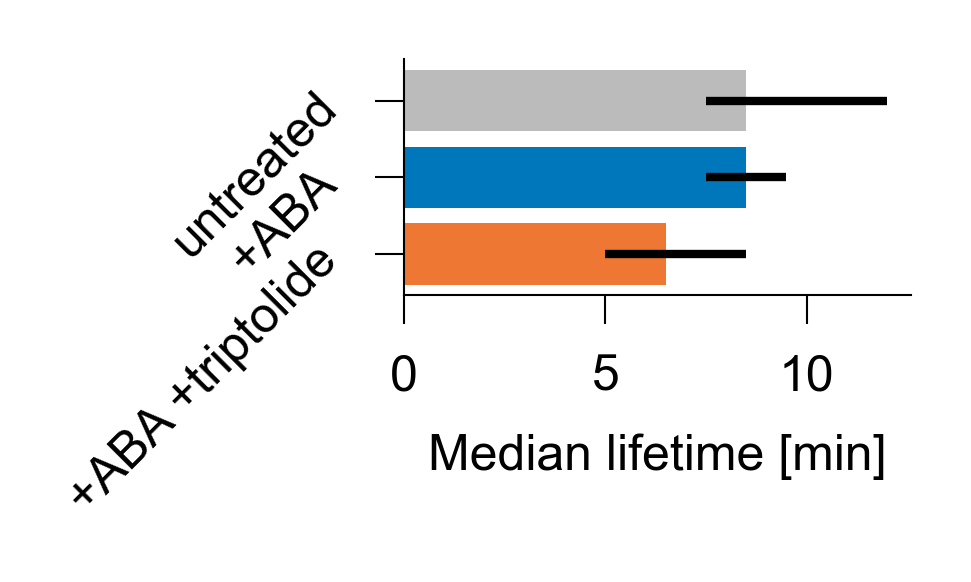

In [40]:
fig, ax = plt.subplots(figsize=(1.6,0.9), dpi=300, frameon=False)

y=2
for condition in conditions_to_plot:
    m, m_ci = loop_lifetimes_medians_and_CIs[condition]
    x = m
    ax.barh(width=[x], y=[y], color=colors_dict[condition], xerr=[[m-m_ci[0]], [m_ci[1]-m]])
    y-=1

ax.set_yticks([2,1,0], [names_dict[condition] for condition in conditions_to_plot],rotation=45,ha='right')
ax.set_xlabel('Median lifetime [min]')

# ax.set_ylim(0, 13);
ax.spines[['top', 'right']].set_visible(False);
fig.align_xlabels()
plt.tight_layout()
plt.savefig(f'{figures_path}/loop_lifetimes_horizontal.svg',transparent=True,bbox_inches='tight')

# Obsolete: Bootstrap distributions of looped fraction

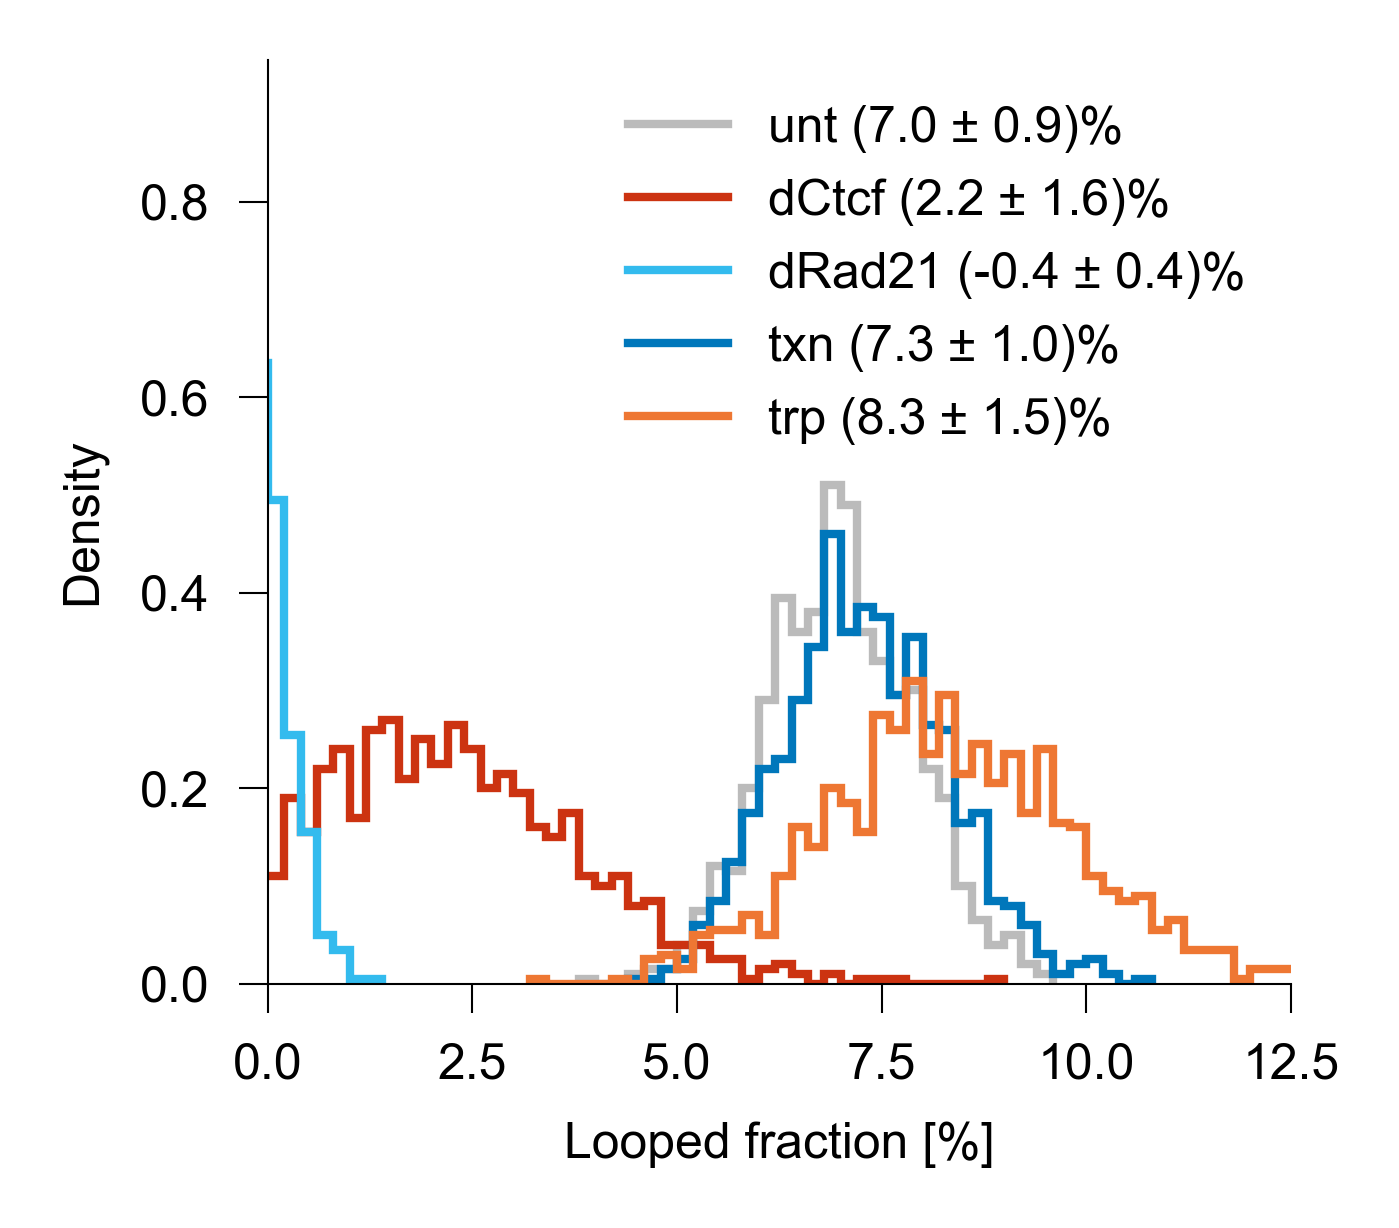

In [44]:
fig, ax = plt.subplots(figsize=(2.2,2.0), dpi=300)
binsize = 0.2

for condition in conditions:
    bootstrap_dist = corrected_looped_frac_bootstrap_dists[condition]

    lower = np.divmod(np.min(bootstrap_dist),binsize)[0]*binsize
    upper = (np.divmod(np.max(bootstrap_dist),binsize)[0]+2)*binsize
    y, x = np.histogram(bootstrap_dist, bins=np.arange(lower, upper, binsize), density=True)
    mean = np.mean(bootstrap_dist)
    std = np.std(bootstrap_dist)
    ax.stairs(y, x, color=colors_dict[condition], label=f'{condition} ({mean:.1f} ± {std:.1f})%');

ax.legend()
ax.set_xlabel('Looped fraction [%]')
ax.set_xlim(0, 12.5);
ax.set_ylabel('Density')
ax.spines[['top', 'right']].set_visible(False)

plt.show();


In [50]:
len(lifetime_bootstrap_dists['unt'])

1000

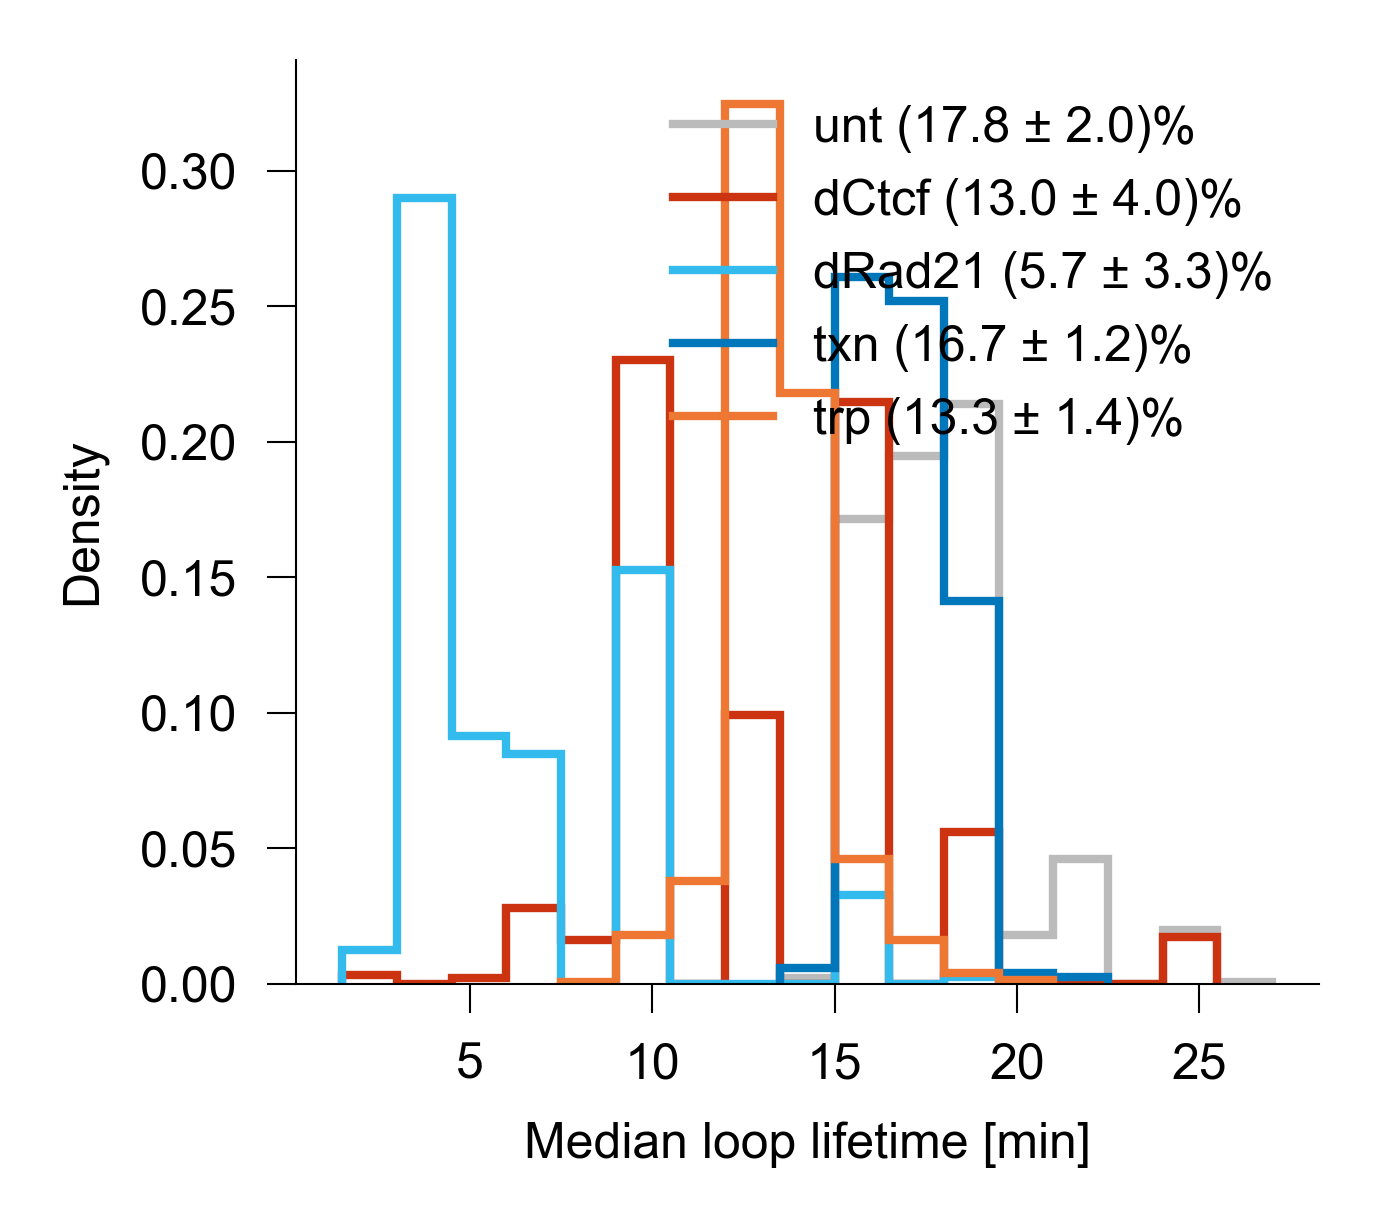

In [53]:
fig, ax = plt.subplots(figsize=(2.2,2.0), dpi=300)
binsize = 1.5

for condition in conditions:
    bootstrap_dist = lifetime_bootstrap_dists[condition]

    lower = np.divmod(np.min(bootstrap_dist),binsize)[0]*binsize
    upper = (np.divmod(np.max(bootstrap_dist),binsize)[0]+2)*binsize
    y, x = np.histogram(bootstrap_dist, bins=np.arange(lower, upper, binsize), density=True)
    mean = np.mean(bootstrap_dist)
    std = np.std(bootstrap_dist)
    ax.stairs(y, x, color=colors_dict[condition], label=f'{condition} ({mean:.1f} ± {std:.1f})%');

ax.legend()
ax.set_xlabel('Median loop lifetime [min]')
# ax.set_xlim(0, 12.5);
ax.set_ylabel('Density')
ax.spines[['top', 'right']].set_visible(False)

plt.show();